In [ ]:
import marimo as mo

# Template industrial con SAM3.1 destilado a EfficientViT-SAM-L1 (cambia carpetas y corre)
SAM3.1 solo hace de **teacher**: genera las máscaras una vez y se descarga de la VRAM.
El pipeline de producción segmenta con el **estudiante EfficientViT-SAM-L1 FP32** (§1b-§1c),
~20x más rápido que SAM (1.24 s -> 0.062 s medidos), y encima corre DINO-masked + EffAD + fusión.
§9-§12 añaden NVTX, benchmark sin profiler, captura Nsight Systems y validación de la traza.
Todo deriva de la config de §0: para otra pieza cambia GOOD_DIR/BAD_DIR y corre de arriba a abajo.
Copia de industrial_sam31.py; el teacher y la clasificación no cambian, solo quién segmenta.

In [ ]:
# §0 Proposito: TODA la configuracion en un solo lugar + logs tic/toc. Lo unico que se edita por pieza.
from pathlib import Path

PROJECT_NAME = "transistor_binary"  # cambia por pieza, p.ej. "tuerca_m10"
DATA_ROOT = Path("data/processed/transistor_binary")
GOOD_DIR = DATA_ROOT / "good"  # solo cambiar estas dos carpetas por pieza
BAD_DIR = DATA_ROOT / "bad"
BACKBONE_ID = "facebook/dinov2-base"
SAM_CHECKPOINT = "models/sam3.1_multiplex.pt"  # peso local gated (descargar de facebook/sam3.1 una vez)
# Estudiante que reemplaza a SAM en produccion (SAM solo hace de teacher en §1).
EVIT_NAME = "efficientvit-sam-l1"
EVIT_REPO = Path("models") / PROJECT_NAME / "sam_distillation" / "vendor" / "efficientvit"
EVIT_WEIGHTS = Path("models") / PROJECT_NAME / "sam_distillation" / "pretrained"
EVIT_SIDE = 512
EVIT_EPOCHS = 30
EVIT_BATCH = 2
EVIT_LR = 1e-5  # FP32: FP16/BF16 dieron perdida no finita en esta arquitectura
EVIT_VAL_FRAC = 0.2  # val sale SOLO del split train; el test nunca entra a la destilacion
# Pon aqui un best.pt ya destilado para saltarte las ~25 min de entreno. El de la campana previa:
# models/transistor_binary/sam_distillation/c1743b64b515a6ee/20261110T081240_360939Z/training/efficientvit-sam-l1/best.pt
# (mismo split: su test coincide con el de §0, sin fuga; epoca 27/30, val Dice del propio entreno)
EVIT_IMPORT_CKPT = None
EFFAD_SIZE = "medium"
STEPS = 5000
DINO_VARIANT = "masked"  # ADOPT Fase I: dino va enmascarado
EFFAD_VARIANT = "none"  # EffAD se queda en original (masked lo rompe: 0.625)
# Fijadas tras Fase I: el resto del codigo asume dino=masked y effad=none sin ramificar.
assert DINO_VARIANT == "masked" and EFFAD_VARIANT == "none", "variantes fijadas: el pipeline asume dino=masked, effad=none"
TEST_SIZE = 0.2
SEED = 42
SAM_PADDING = 0.08
MIN_MASK_AREA_RATIO = 0.03
MAX_MASK_AREA_RATIO = 0.85
N_BOOT = 200
MLFLOW_URI = "sqlite:///mlflow.db"
MLFLOW_EXPERIMENT = PROJECT_NAME
MODELS_DIR = Path("models") / PROJECT_NAME / "prod_sam31_distill"
FIG_DIR = Path("reports/figures") / f"{PROJECT_NAME}_sam31_distill"
PROFILE_DIR = Path("reports/profiling") / PROJECT_NAME / "sam31_distill"
BENCH_WARMUPS = 5  # frames de calentamiento fuera de toda estadistica
BENCH_REPEATS = 30  # mediciones por escenario del §10
import os as _os0
# CAPTURE_MODE=1 solo dentro del proceso hijo que lanza Nsight (§11): evita relanzar nada al abrir.
CAPTURE_MODE = _os0.environ.get("QC31D_CAPTURE", "0") == "1"
TRACE_DIR = _os0.environ.get("QC31D_TRACE_DIR")
FIG_DIR.mkdir(parents=True, exist_ok=True)  # lo crean tarde en §6; los mosaicos de §2 lo necesitan antes

# Log de corridas: toda celda pesada llama tic/toc + prints internos por fold/foto.
import time as _tlog
TIC = {}

def tic(name):
    TIC[name] = _tlog.time()
    print("[%s] inicio %s" % (_tlog.strftime("%H:%M:%S"), name), flush=True)

def toc(name):
    _dt = _tlog.time() - TIC.pop(name, _tlog.time())
    print("[%s] fin %s (%.1fs)" % (_tlog.strftime("%H:%M:%S"), name, _dt), flush=True)
import numpy as np
import pandas as pd
import hashlib
import matplotlib.pyplot as plt

### §0 Datos: escanea carpetas, arma labels y fingerprint (aborta si falta algo)

In [ ]:
# §0 Proposito: inventario del dataset (filename, label, path) + split train/test + fingerprint.

from sklearn.model_selection import StratifiedShuffleSplit

_recs = [{"filename": p.name, "label": "good", "path": str(p)} for p in sorted(GOOD_DIR.glob("*")) if p.is_file()]
_recs += [{"filename": p.name, "label": "bad", "path": str(p)} for p in sorted(BAD_DIR.glob("*")) if p.is_file()]
assert _recs, f"carpetas vacias: {GOOD_DIR} {BAD_DIR}"
df_files = pd.DataFrame(_recs)
assert not df_files.filename.duplicated().any(), "filenames duplicados entre good/bad"
print(f"dataset: {(df_files.label == 'good').sum()} GOOD + {(df_files.label == 'bad').sum()} BAD")
fingerprint = hashlib.sha1("|".join(sorted(f"{r.filename}:{(GOOD_DIR / r.filename if r.label == 'good' else BAD_DIR / r.filename).stat().st_size}" for r in df_files.itertuples())).encode()).hexdigest()[:16]
print("fingerprint:", fingerprint)
_y0 = (df_files.label == "bad").to_numpy(int)
_tr, _te = next(StratifiedShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED).split(df_files, _y0))
train_files = df_files.iloc[_tr].reset_index(drop=True)
test_files = df_files.iloc[_te].reset_index(drop=True)
print(f"split: {len(train_files)} train ({(train_files.label == 'bad').sum()} BAD) + {len(test_files)} test ({(test_files.label == 'bad').sum()} BAD)")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

dataset: 273 GOOD + 40 BAD
fingerprint: 943ae352501916c0
split: 250 train (32 BAD) + 63 test (8 BAD)


### §1 SAM teacher: segmenta una vez, guarda máscaras y se descarga de la VRAM

In [ ]:
# §1 Proposito: carga SAM3.1 una vez + funciones mascara/bbox/crop. Solo localiza, nunca clasifica.
# ponytail: ultralytics (no transformers) porque facebook/sam3.1 no trae model.safetensors,
# solo sam3.1_multiplex.pt; si HF publica safetensors, volver a Sam3Model y borrar la dependencia.
import time
from pathlib import Path as _Path

import torch
from PIL import Image
from transformers import AutoImageProcessor, AutoModel
from ultralytics.models.sam import SAM3SemanticPredictor

tic("sam_load")
assert _Path(SAM_CHECKPOINT).exists(), f"falta peso SAM3.1: {SAM_CHECKPOINT} (bajar de facebook/sam3.1)"
# Cache del predictor en un nombre NORMAL: `global _sam` no pegaba porque los privados
# tienen scope de celda en marimo, asi que SAM se reconstruia en CADA foto (26s recargando
# el checkpoint + 10s inicializando pesos, con 1.2s de inferencia real).
SAM_CACHE = {}  # lo llena segment_part, lo vacia unload_sam()
_sam_overrides = {
    "conf": 0.05, "task": "segment", "mode": "predict",
    "model": SAM_CHECKPOINT, "imgsz": 1036, "verbose": False, "save": False,  # 1036 = multiplo de stride 14 (callado)
}
_sam_dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("sam device:", _sam_dev)


def segment_part(image, prompt="transistor"):
    _t0 = time.perf_counter()  # el reloj incluye la construccion: antes la escondia
    _sam = SAM_CACHE.get("predictor")
    if _sam is None:
        _sam = SAM_CACHE["predictor"] = SAM3SemanticPredictor(overrides=_sam_overrides)
        print("SAM construido una vez (%.1fs)" % (time.perf_counter() - _t0), flush=True)
    _sam.set_image(np.asarray(image.convert("RGB"))[:, :, ::-1])  # PIL RGB -> BGR (cv2)
    _r = _sam(text=[prompt])[0]
    if _r.masks is None:
        return {"mask": np.zeros((image.size[1], image.size[0]), bool), "score": 0.0,
                "latency": time.perf_counter() - _t0}
    _qi = int(_r.boxes.conf.cpu().numpy().argmax())
    return {"mask": _r.masks.data[_qi].cpu().numpy().astype(bool),
            "score": float(_r.boxes.conf[_qi]), "latency": time.perf_counter() - _t0}


def mask_to_bbox(mask):
    _ys, _xs = np.where(np.asarray(mask))
    if len(_xs) == 0:
        return None
    return (int(_xs.min()), int(_ys.min()), int(_xs.max()), int(_ys.max()))


def expand_bbox(bbox, image_shape, padding_ratio=0.08):
    _h, _w = image_shape[:2]
    _x0, _y0, _x1, _y1 = bbox
    _bw, _bh = _x1 - _x0, _y1 - _y0
    _px, _py = int(_bw * padding_ratio), int(_bh * padding_ratio)
    return (max(0, _x0 - _px), max(0, _y0 - _py), min(_w, _x1 + _px), min(_h, _y1 + _py))



def unload_sam():
    SAM_CACHE.pop("predictor", None)
    import gc as _gc
    _gc.collect()
    torch.cuda.empty_cache()
    print("sam descargado, VRAM:", round(torch.cuda.memory_allocated() / 1e9, 2), "GB")

toc("sam_load")

[04:42:10] inicio sam_load
sam device: cuda
[04:42:10] fin sam_load (0.0s)


In [ ]:
# §1 Proposito: mascaras teacher de TODO el dataset con log cada 10 (o reusa cache por fingerprint).
# Las PNG a resolucion completa son el TARGET de la destilacion (§1b); las 256 son para figuras/QC.

tic("teacher_cache")
_t_dir = MODELS_DIR / "teacher"
teacher_mask_dir = _t_dir / "masks"
teacher_mask_dir.mkdir(parents=True, exist_ok=True)
_csv, _pt = _t_dir / "masks.csv", _t_dir / "masks256.pt"
_fp_file = _t_dir / "fingerprint.txt"
_png_ok = all((teacher_mask_dir / _f).is_file() for _f in df_files.filename)
if _csv.exists() and _fp_file.exists() and _fp_file.read_text().strip() == fingerprint and _png_ok:
    teacher_masks = pd.read_csv(_csv)
    _mp = torch.load(_pt, map_location="cpu", weights_only=False)
    teacher_masks256, _mfn = _mp["masks"], _mp["fnames"]
    print(f"teacher cache hit: {len(teacher_masks)} filas + PNG full-res")
else:
    _rows, _ml, _mfn = [], [], []
    for _k, _r in enumerate(df_files.itertuples()):
        _im = Image.open(_r.path).convert("RGB")
        _s = segment_part(_im)
        _bb = mask_to_bbox(_s["mask"])
        _m = _s["mask"]
        _rows.append({"filename": _r.filename, "label": _r.label, "score": round(_s["score"], 3),
                       "area": round(float(_m.mean()), 4), "bbox": _bb is not None,
                       "edge": bool(_m[0, :].any() or _m[-1, :].any() or _m[:, 0].any() or _m[:, -1].any()),
                       "lat": round(_s["latency"], 2),
                       "x0": _bb[0] if _bb else -1, "y0": _bb[1] if _bb else -1,
                       "x1": _bb[2] if _bb else -1, "y1": _bb[3] if _bb else -1})
        Image.fromarray(_m.astype("uint8") * 255).save(teacher_mask_dir / _r.filename)
        _ml.append(torch.from_numpy(np.array(Image.fromarray(_m.astype("uint8") * 255).resize((256, 256))) > 0))
        _mfn.append(_r.filename)
        if (_k + 1) % 10 == 0:
            print(f"teacher {_k + 1}/{len(df_files)}", flush=True)
    teacher_masks = pd.DataFrame(_rows)
    teacher_masks.to_csv(_csv, index=False)
    teacher_masks256 = torch.stack(_ml)
    torch.save({"masks": teacher_masks256, "fnames": _mfn}, _pt)
    _fp_file.write_text(fingerprint)
    print(f"saved {len(teacher_masks)} mascaras teacher (csv + PNG + 256)")
print(f"bbox_ok={teacher_masks.bbox.mean():.3f} edge={teacher_masks.edge.mean():.3f} lat_media={teacher_masks.lat.mean():.2f}s total={teacher_masks.lat.sum() / 60:.1f}min")
unload_sam()  # SAM ya no se usa en vivo: libera ~6GB para destilar y entrenar
toc("teacher_cache")

[04:42:10] inicio teacher_cache
teacher cache hit: 313 filas + PNG full-res
bbox_ok=1.000 edge=0.013 lat_media=1.59s total=8.3min
sam descargado, VRAM: 0.0 GB
[04:42:10] fin teacher_cache (0.2s)


### §1b Destilación: EfficientViT-SAM-L1 FP32 aprende las máscaras del teacher (solo split train)

In [ ]:
# §1b Proposito: helpers del estudiante (carga, letterbox, target, metricas de mascara, NVTX).
# El decoder recibe SIEMPRE una caja fija de cuadro completo: nunca la caja real del teacher,
# para que el estudiante aprenda a localizar solo y la inferencia no necesite oracle.
import contextlib as _ctx
import sys as _sys
import torch.nn.functional as TF

class Student(torch.nn.Module):
    def __init__(self, _core):
        super().__init__()
        self.sam = _core

    def forward(self, _x):
        _emb = self.sam.image_encoder(_x)
        _box = _x.new_tensor([[0.0, 0.0, 1024.0, 1024.0]])
        _sparse, _dense = self.sam.prompt_encoder(points=None, boxes=_box, masks=None)
        _logits, _ = self.sam.mask_decoder(
            image_embeddings=_emb, image_pe=self.sam.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=_sparse, dense_prompt_embeddings=_dense,
            multimask_output=False)
        return TF.interpolate(_logits, size=_x.shape[-2:], mode="bilinear", align_corners=False)

def load_student(checkpoint=None):
    _repo = EVIT_REPO.resolve()
    if _repo.is_dir() and str(_repo) not in _sys.path:
        _sys.path.insert(0, str(_repo))  # checkout oficial mit-han-lab/efficientvit
    from efficientvit.sam_model_zoo import create_sam_model

    _w = EVIT_WEIGHTS / (EVIT_NAME.replace("-", "_") + ".pt")
    assert checkpoint is not None or _w.is_file(), f"falta el peso oficial {_w}"
    _core = create_sam_model(name=EVIT_NAME.rsplit("-", 1)[-1], pretrained=checkpoint is None,
                             **({"weight_url": str(_w)} if checkpoint is None else {}))
    _st = Student(_core)
    if checkpoint is not None:
        _st.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True)["state_dict"])
    return _st

def nvtx_range(name, enabled=False):
    # NVTX solo cuando se pide: el benchmark del §10 mide SIN rangos.
    return torch.cuda.nvtx.range("qc31d/" + name) if enabled else _ctx.nullcontext()

def prepare_tensor(image, side, nvtx=False):
    # Letterbox centrado + normalizacion ImageNet: identico al entreno (el ckpt depende de esto).
    _h, _w = image.shape[:2]
    _ratio = min(side / _h, side / _w)
    _rh, _rw = round(_h * _ratio), round(_w * _ratio)
    _top, _left = (side - _rh) // 2, (side - _rw) // 2
    with nvtx_range("h2d", nvtx):
        _px = torch.from_numpy(image).to("cuda").permute(2, 0, 1).unsqueeze(0)
    with nvtx_range("preprocess", nvtx):
        _x = TF.interpolate(_px.float(), size=(_rh, _rw), mode="bilinear", align_corners=False)
        _x = TF.pad(_x, (_left, side - _rw - _left, _top, side - _rh - _top), value=0) / 255
        _mean = _x.new_tensor([0.485, 0.456, 0.406])[None, :, None, None]
        _std = _x.new_tensor([0.229, 0.224, 0.225])[None, :, None, None]
        _x = (_x - _mean) / _std
    return _x.contiguous(), (_h, _w, _rh, _rw, _top, _left)

def target_tensor(mask, geometry, side):
    _, _, _rh, _rw, _top, _left = geometry
    _t = torch.from_numpy(np.asarray(mask).astype("float32")).to("cuda")[None, None]
    _t = TF.interpolate(_t, size=(_rh, _rw), mode="nearest")
    return TF.pad(_t, (_left, side - _rw - _left, _top, side - _rh - _top))

def restore_mask(probability, geometry):
    _h, _w, _rh, _rw, _top, _left = geometry
    _m = probability[..., _top:_top + _rh, _left:_left + _rw]
    _m = TF.interpolate(_m.float(), size=(_h, _w), mode="bilinear", align_corners=False)
    return (_m[0, 0] > 0.5).detach().cpu().numpy()

def mask_metrics(prediction, target):
    # Acuerdo con el teacher, NO exactitud frente a etiqueta humana.
    import cv2

    _p, _t = np.asarray(prediction).astype(bool), np.asarray(target).astype(bool)
    assert _p.shape == _t.shape, f"formas distintas {_p.shape} vs {_t.shape}"
    _inter, _union = np.logical_and(_p, _t).sum(), np.logical_or(_p, _t).sum()
    _k, _tol = np.ones((3, 3), np.uint8), np.ones((5, 5), np.uint8)
    _pe = _p & ~cv2.erode(_p.astype(np.uint8), _k).astype(bool)
    _te = _t & ~cv2.erode(_t.astype(np.uint8), _k).astype(bool)
    _prec = float((_pe & cv2.dilate(_te.astype(np.uint8), _tol).astype(bool)).sum() / max(int(_pe.sum()), 1))
    _rec = float((_te & cv2.dilate(_pe.astype(np.uint8), _tol).astype(bool)).sum() / max(int(_te.sum()), 1))
    return {"iou": float(_inter / max(int(_union), 1)),
            "dice": float(2 * _inter / max(int(_p.sum() + _t.sum()), 1)),
            "boundary_f1": 2 * _prec * _rec / max(_prec + _rec, 1e-12),
            "empty_mask": float(not _p.any())}  # NO "empty": choca con DataFrame.empty

print("helpers del estudiante listos:", EVIT_NAME)

helpers del estudiante listos: efficientvit-sam-l1


In [ ]:
# §1b Proposito: destila SAM -> EfficientViT-SAM-L1 usando SOLO el split train (test cerrado).
# ponytail: FP32 porque FP16 y BF16 dieron perdida no finita en esta arquitectura (medido en
# industrial_sam_distill.py); si una version futura la estabiliza, bajar precision y remedir.
import math as _math
import shutil as _shutil
from sklearn.model_selection import StratifiedShuffleSplit as _SSS2

tic("distill_train")
_dir = MODELS_DIR / "student"
_dir.mkdir(parents=True, exist_ok=True)
student_ckpt = _dir / "best.pt"
_resume = _dir / "last_training.pt"
_logcsv = _dir / "light_logs.csv"

if EVIT_IMPORT_CKPT and not student_ckpt.exists():
    _shutil.copy2(EVIT_IMPORT_CKPT, student_ckpt)  # reusa un best.pt ya destilado: ahorra ~25 min
    print("importado checkpoint destilado:", EVIT_IMPORT_CKPT, flush=True)

# El val de la destilacion sale del split train: el estudiante jamas ve una foto de test.
_ytr = (train_files.label == "bad").to_numpy(int)
_tri, _vai = next(_SSS2(n_splits=1, test_size=EVIT_VAL_FRAC, random_state=SEED).split(train_files, _ytr))
_parts = {"train": train_files.iloc[_tri].reset_index(drop=True),
          "val": train_files.iloc[_vai].reset_index(drop=True)}
print(f"destilacion: {len(_parts['train'])} train + {len(_parts['val'])} val, targets = mascaras teacher")

_skip = False
if student_ckpt.exists():
    _meta = torch.load(student_ckpt, map_location="cpu", weights_only=False)
    if _meta.get("fingerprint") is None:
        _skip = True
        print("estudiante importado (sin fingerprint propio): no se reentrena", flush=True)
    elif _meta.get("fingerprint") == fingerprint and _resume.is_file():
        _prog = torch.load(_resume, map_location="cpu", weights_only=False)
        _skip = int(_prog.get("next_epoch", 0)) >= EVIT_EPOCHS
        print(f"progreso previo {_prog.get('next_epoch')}/{EVIT_EPOCHS} -> {'cache hit' if _skip else 'reanuda'}", flush=True)
        del _prog
    else:
        print("checkpoint de otro dataset o sin progreso: reentrena desde el peso oficial", flush=True)

if not _skip:
    _model = load_student().cuda().float()
    _opt = torch.optim.AdamW(_model.parameters(), lr=EVIT_LR, weight_decay=1e-4)
    _rng = np.random.default_rng(SEED)
    _rows, _best_dice, _start = [], -1.0, 0
    if _resume.is_file():
        _sv = torch.load(_resume, map_location="cpu", weights_only=False)  # payload propio con numpy
        assert (_sv["fingerprint"] == fingerprint and _sv["batch"] == EVIT_BATCH and _sv.get("side") == EVIT_SIDE and _sv.get("lr") == EVIT_LR and _sv.get("epochs") == EVIT_EPOCHS and _sv.get("val_frac") == EVIT_VAL_FRAC), "resume de otro dataset/hiperparametros"
        _model.load_state_dict(_sv["state_dict"])
        _opt.load_state_dict(_sv["optimizer"])
        _rng.bit_generator.state = _sv["numpy_rng"]
        torch.set_rng_state(_sv["torch_rng"])
        torch.cuda.set_rng_state(_sv["cuda_rng"])
        _rows, _best_dice, _start = _sv["rows"], _sv["best_dice"], int(_sv["next_epoch"])
        print("reanudando en la epoca", _start + 1, flush=True)
        del _sv
    else:
        torch.manual_seed(SEED)
    for _ep in range(_start, EVIT_EPOCHS):
        _em = {}
        for _part in ("train", "val"):
            _training = _part == "train"
            _model.train(_training)
            if _training:
                for _mod in _model.modules():  # BN congelado: lotes de 2 no dan estadisticas utiles
                    if isinstance(_mod, torch.nn.modules.batchnorm._BatchNorm):
                        _mod.eval()
            _sub = _parts[_part]
            _order = list(_rng.permutation(len(_sub))) if _training else list(range(len(_sub)))
            _losses, _dices = [], []
            for _off in range(0, len(_order), EVIT_BATCH):
                _xs, _ts = [], []
                for _pi in _order[_off:_off + EVIT_BATCH]:
                    _row = _sub.iloc[int(_pi)]
                    _img = np.array(Image.open(_row.path).convert("RGB"), copy=True)
                    _x1, _geo = prepare_tensor(_img, EVIT_SIDE)
                    _t1 = target_tensor(np.array(Image.open(teacher_mask_dir / _row.filename)) > 127, _geo, EVIT_SIDE)
                    if _training and _rng.random() < 0.5:
                        _x1, _t1 = _x1.flip(-1), _t1.flip(-1)
                    _xs.append(_x1)
                    _ts.append(_t1)
                _x, _t = torch.cat(_xs), torch.cat(_ts)
                with torch.set_grad_enabled(_training), torch.autocast("cuda", enabled=False):
                    _logits = _model(_x)
                _prob = _logits.float().sigmoid()  # sumas en FP32: medio millon de pixeles por mascara
                _sd = (2 * (_prob * _t).sum() + 1) / (_prob.sum() + _t.sum() + 1)
                _loss = TF.binary_cross_entropy_with_logits(_logits.float(), _t) + 1 - _sd
                assert torch.isfinite(_loss), "perdida no finita: no sigas entrenando"
                if _training:
                    _opt.zero_grad(set_to_none=True)
                    _loss.backward()
                    torch.nn.utils.clip_grad_norm_(_model.parameters(), 1.0, error_if_nonfinite=True)
                    _opt.step()
                _losses.append(float(_loss.detach()))
                _dices.append(float(_sd.detach()))
                if (_off // EVIT_BATCH + 1) % 20 == 0:
                    print("ep%d %s lote %d/%d loss=%.4f dice=%.4f" % (
                        _ep + 1, _part, _off // EVIT_BATCH + 1,
                        _math.ceil(len(_order) / EVIT_BATCH), _losses[-1], _dices[-1]), flush=True)
            _em[_part + "_loss"] = float(np.mean(_losses))
            _em[_part + "_dice"] = float(np.mean(_dices))
        _rows.append(dict(epoch=_ep + 1, **_em))
        pd.DataFrame(_rows).to_csv(_logcsv, index=False)
        print(f"epoca {_ep + 1}/{EVIT_EPOCHS} {_em}", flush=True)
        if _em["val_dice"] > _best_dice:
            _best_dice = _em["val_dice"]
            torch.save({"state_dict": {k: v.detach().cpu() for k, v in _model.state_dict().items()},
                        "candidate": EVIT_NAME, "side": EVIT_SIDE, "epoch": _ep + 1,
                        "val_dice": _best_dice, "precision": "fp32", "batch": EVIT_BATCH, "lr": EVIT_LR, "epochs": EVIT_EPOCHS, "val_frac": EVIT_VAL_FRAC,
                        "fingerprint": fingerprint}, student_ckpt)
            print("  nuevo mejor val_dice:", round(_best_dice, 4), flush=True)
        _tmp = _dir / "last_training.tmp"  # escritura atomica: reanudar sin perder la epoca
        torch.save({"state_dict": _model.state_dict(), "optimizer": _opt.state_dict(),
                    "numpy_rng": _rng.bit_generator.state, "torch_rng": torch.get_rng_state(),
                    "cuda_rng": torch.cuda.get_rng_state(), "rows": _rows,
                    "best_dice": _best_dice, "next_epoch": _ep + 1,
                    "fingerprint": fingerprint, "batch": EVIT_BATCH, "side": EVIT_SIDE, "lr": EVIT_LR, "epochs": EVIT_EPOCHS, "val_frac": EVIT_VAL_FRAC}, _tmp)
        _tmp.replace(_resume)
    _model.to("cpu")
    del _model, _opt
    import gc as _gc1

    _gc1.collect()
    torch.cuda.empty_cache()
    print("estudiante entrenado, VRAM:", round(torch.cuda.memory_allocated() / 1e9, 2), "GB")

distill_log = pd.read_csv(_logcsv) if _logcsv.exists() else pd.DataFrame()
assert student_ckpt.exists(), "no hay checkpoint del estudiante"
print("checkpoint:", student_ckpt, "| epocas registradas:", len(distill_log))
toc("distill_train")

[04:42:10] inicio distill_train
destilacion: 200 train + 50 val, targets = mascaras teacher
progreso previo 30/30 -> cache hit
checkpoint: models\transistor_binary\prod_sam31_distill\student\best.pt | epocas registradas: 30
[04:42:11] fin distill_train (0.4s)


### §1c Máscaras del estudiante: reemplazan las del teacher en el pipeline + calidad y latencia

In [ ]:
# §1c Proposito: el estudiante segmenta TODO el dataset; de aqui en adelante el pipeline usa
# estas mascaras (mismas columnas que el teacher), nunca mas SAM. Calidad = acuerdo con teacher.
import json as _json1

tic("student_masks")
_sdir = MODELS_DIR / "student"
_csv, _pt = _sdir / "masks.csv", _sdir / "masks256.pt"
_qcsv, _rjson = _sdir / "quality.csv", _sdir / "speed.json"
_ck_sha = hashlib.sha256(student_ckpt.read_bytes()).hexdigest()[:16]
_stamp = f"{fingerprint}:{_ck_sha}"
_fp_file = _sdir / "masks_fingerprint.txt"

if _csv.exists() and _fp_file.exists() and _fp_file.read_text().strip() == _stamp:
    sam_masks = pd.read_csv(_csv)
    _mp2 = torch.load(_pt, map_location="cpu", weights_only=False)
    sam_masks256 = _mp2["masks"]
    student_quality = pd.read_csv(_qcsv)
    student_speed = _json1.loads(_rjson.read_text())
    print(f"student cache hit: {len(sam_masks)} mascaras (ckpt {_ck_sha})")
else:
    _model = load_student(student_ckpt).cuda().float().eval()
    _mdir = _sdir / "masks_png"
    _mdir.mkdir(parents=True, exist_ok=True)
    _warm = [np.array(Image.open(_r.path).convert("RGB"), copy=True) for _r in df_files.head(3).itertuples()]
    with torch.inference_mode():
        for _w in _warm:  # calentamiento fuera de toda estadistica
            _xw, _gw = prepare_tensor(_w, EVIT_SIDE)
            restore_mask(_model(_xw).float().sigmoid(), _gw)
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    _rows, _ml, _qrows, _fwd = [], [], [], []
    import time as _t1

    for _k, _r in enumerate(df_files.itertuples()):
        _img = np.array(Image.open(_r.path).convert("RGB"), copy=True)
        torch.cuda.synchronize()
        _t0 = _t1.perf_counter()
        with torch.inference_mode():
            _x, _geo = prepare_tensor(_img, EVIT_SIDE)
            _prob = _model(_x).float().sigmoid()
            _m = restore_mask(_prob, _geo)
        torch.cuda.synchronize()
        _seg_ms = (_t1.perf_counter() - _t0) * 1000
        # Medicion aparte: solo la red, con la entrada ya residente (CUDA events).
        _e0, _e1 = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
        with torch.inference_mode():
            _e0.record()
            _ = _model(_x)
            _e1.record()
            _e1.synchronize()
        _fwd.append(_e0.elapsed_time(_e1))
        _bb = mask_to_bbox(_m)
        _rows.append({"filename": _r.filename, "label": _r.label,
                      "score": round(float(_prob.max()), 3),
                      "area": round(float(_m.mean()), 4), "bbox": _bb is not None,
                      "edge": bool(_m[0, :].any() or _m[-1, :].any() or _m[:, 0].any() or _m[:, -1].any()),
                      "lat": round(_seg_ms / 1000, 4),
                      "x0": _bb[0] if _bb else -1, "y0": _bb[1] if _bb else -1,
                      "x1": _bb[2] if _bb else -1, "y1": _bb[3] if _bb else -1,
                      "seg_ms": round(_seg_ms, 2), "fwd_ms": round(_fwd[-1], 2)})
        _ml.append(torch.from_numpy(np.array(Image.fromarray(_m.astype("uint8") * 255).resize((256, 256))) > 0))
        Image.fromarray(_m.astype("uint8") * 255).save(_mdir / _r.filename)
        _tm = np.array(Image.open(teacher_mask_dir / _r.filename)) > 127
        _qrows.append({"filename": _r.filename, "label": _r.label, **mask_metrics(_m, _tm)})
        if (_k + 1) % 25 == 0:
            print(f"student {_k + 1}/{len(df_files)} seg={_seg_ms:.1f}ms iou={_qrows[-1]['iou']:.3f}", flush=True)
    sam_masks = pd.DataFrame(_rows)
    sam_masks.to_csv(_csv, index=False)
    sam_masks256 = torch.stack(_ml)
    torch.save({"masks": sam_masks256, "fnames": list(sam_masks.filename)}, _pt)
    student_quality = pd.DataFrame(_qrows)
    student_quality.to_csv(_qcsv, index=False)
    student_speed = {
        "checkpoint_sha256_16": _ck_sha, "side": EVIT_SIDE, "images": len(sam_masks),
        "fwd_cuda_ms_median": float(np.median(_fwd)), "fwd_cuda_ms_p95": float(np.quantile(_fwd, 0.95)),
        "seg_ms_median": float(sam_masks.seg_ms.median()), "seg_ms_p95": float(sam_masks.seg_ms.quantile(0.95)),
        "teacher_seg_ms_median": float(teacher_masks.lat.median() * 1000),
        "teacher_seg_ms_median_no_first": float(teacher_masks.lat.iloc[1:].median() * 1000),
        "speedup_vs_teacher": float(teacher_masks.lat.median() * 1000 / sam_masks.seg_ms.median()),
        "speedup_vs_teacher_no_first": float(teacher_masks.lat.iloc[1:].median() * 1000 / sam_masks.seg_ms.median()),
        "peak_allocated_gb": torch.cuda.max_memory_allocated() / 1e9,
        "nota": "batch=1, incluye preparacion y vuelta de la mascara a CPU; sin profiler ni NVTX",
    }
    _rjson.write_text(_json1.dumps(student_speed, indent=2), encoding="utf-8")
    _model.to("cpu")
    del _model
    import gc as _gc2

    _gc2.collect()
    torch.cuda.empty_cache()
    _fp_file.write_text(_stamp)
    print("saved masks.csv + masks256.pt + quality.csv + speed.json")

print("calidad vs teacher: iou=%.4f dice=%.4f borde_f1=%.4f vacias=%.3f" % (
    student_quality.iou.mean(), student_quality.dice.mean(),
    student_quality.boundary_f1.mean(), student_quality.empty_mask.mean()))
print("por clase:", student_quality.groupby("label").iou.mean().round(4).to_dict())
_tmed_nf = float(student_speed.get("teacher_seg_ms_median_no_first", student_speed["teacher_seg_ms_median"]))
_spd_nf = float(student_speed.get("speedup_vs_teacher_no_first", student_speed["speedup_vs_teacher"]))
print("latencia: red %.1f ms (p95 %.1f) | segmentacion %.1f ms (p95 %.1f) | teacher %.0f ms -> %.1fx (sin 1a foto SAM; legacy %.0f ms -> %.1fx)" % (
    student_speed["fwd_cuda_ms_median"], student_speed["fwd_cuda_ms_p95"],
    student_speed["seg_ms_median"], student_speed["seg_ms_p95"],
    _tmed_nf, _spd_nf, student_speed["teacher_seg_ms_median"], student_speed["speedup_vs_teacher"]))
assert student_quality.empty_mask.mean() == 0, "el estudiante dejo mascaras vacias: revisar antes de seguir"
_fq, _aq = plt.subplots(1, 2, figsize=(11, 4))
_aq[0].hist(student_quality.iou, bins=30, color="#4C78A8")
_aq[0].set(title="IoU estudiante vs teacher", xlabel="IoU", ylabel="n")
for _lb, _c in (("good", "#4C78A8"), ("bad", "#F58518")):
    _s = sam_masks[sam_masks.label == _lb]
    _aq[1].scatter(_s.seg_ms, _s.area, s=12, c=_c, label=_lb)
_aq[1].set(title="latencia vs area de mascara", xlabel="ms por foto", ylabel="area")
_aq[1].legend()
_fq.tight_layout()
_fq.savefig(FIG_DIR / "student_quality.png", dpi=100)
print("saved student_quality.png")
toc("student_masks")

[04:42:11] inicio student_masks
student cache hit: 313 mascaras (ckpt eef17457d57b7d83)
calidad vs teacher: iou=0.9490 dice=0.9715 borde_f1=0.6872 vacias=0.000
por clase: {'bad': 0.8911, 'good': 0.9575}
latencia: red 22.6 ms (p95 29.4) | segmentacion 24.0 ms (p95 30.9) | teacher 1560 ms -> 65.0x (sin 1a foto SAM; legacy 1560 ms -> 65.0x)
saved student_quality.png
[04:42:11] fin student_masks (0.4s)


### §2 Variantes none/crop/masked con las máscaras del estudiante + media GOOD-train (sin fuga)

In [ ]:
# §2 Proposito: construye cada variante con las mascaras del ESTUDIANTE (sam_masks/sam_masks256
# vienen de §1c) + fondo masked = media de GOOD-train (nunca test).
tic("variants")
_pos = dict(zip(sam_masks.filename, range(len(sam_masks))))
_good_tr = train_files[train_files.label == "good"]
_sizes = {}
for _gf in _good_tr.itertuples():
    with Image.open(_gf.path) as _oo:
        _sizes[_oo.size] = _sizes.get(_oo.size, 0) + 1
if len(_sizes) > 1:
    print("AVISO: tamanos heterogeneos en GOOD-train (todo se redimensiona a 1024x1024): " + ", ".join(f"{_w}x{_h}x{_n}" for (_w, _h), _n in sorted(_sizes.items())))
_mean = np.zeros((1024, 1024, 3), np.float64)
for _gf in _good_tr.itertuples():
    _mean += np.asarray(Image.open(_gf.path).convert("RGB").resize((1024, 1024)), np.float64)
good_mean = (_mean / len(_good_tr)).astype("uint8")
print(f"media GOOD-train de {len(_good_tr)} fotos")
_qc = {r.filename: (r.area, r.edge, (r.x0, r.y0, r.x1, r.y1) if r.bbox else None) for r in sam_masks.itertuples()}
_n_fb = []

def build_masked(im_pil, mask_bool):
    # UNICO constructor masked: batch (§2) y produccion (§8) ven la misma imagen.
    _m1024 = np.array(Image.fromarray(np.asarray(mask_bool).astype("uint8") * 255).resize((1024, 1024))) > 0
    return Image.fromarray(np.where(_m1024[:, :, None], np.asarray(im_pil.resize((1024, 1024))), good_mean).astype("uint8"))


def variant_image(filename, path, variant):
    _im = Image.open(path).convert("RGB")
    if variant == "none":
        return _im
    _area, _edge, _bb = _qc[filename]
    if _bb is None or _bb[0] < 0 or _area < MIN_MASK_AREA_RATIO or _area > MAX_MASK_AREA_RATIO or _edge:
        _n_fb.append(filename)
        return _im  # fallback QC: original
    if variant == "crop":
        from PIL import Image as _I  # noqa

        return _im.crop(expand_bbox(_bb, (_im.size[1], _im.size[0]), SAM_PADDING))
    _mk = np.array(Image.open(MODELS_DIR / "student" / "masks_png" / filename)) > 127  # PNG full-res del estudiante, identico a infer()
    return build_masked(_im, _mk)

print("fallback QC activable en:", sorted(set(_n_fb)) if False else "(se cuenta al embeddar)")
good_mean_npy = MODELS_DIR / "good_mean.npy"  # idem para la media GOOD-train que usa §8
np.save(good_mean_npy, good_mean)
print("saved good_mean.npy", good_mean.shape)
toc("variants")

[04:42:11] inicio variants
media GOOD-train de 218 fotos
fallback QC activable en: (se cuenta al embeddar)
saved good_mean.npy (1024, 1024, 3)
[04:42:21] fin variants (9.4s)


[04:42:21] inicio viz_crops
saved ejemplos_good.png
saved ejemplos_bad.png
[04:42:30] fin viz_crops (9.7s)



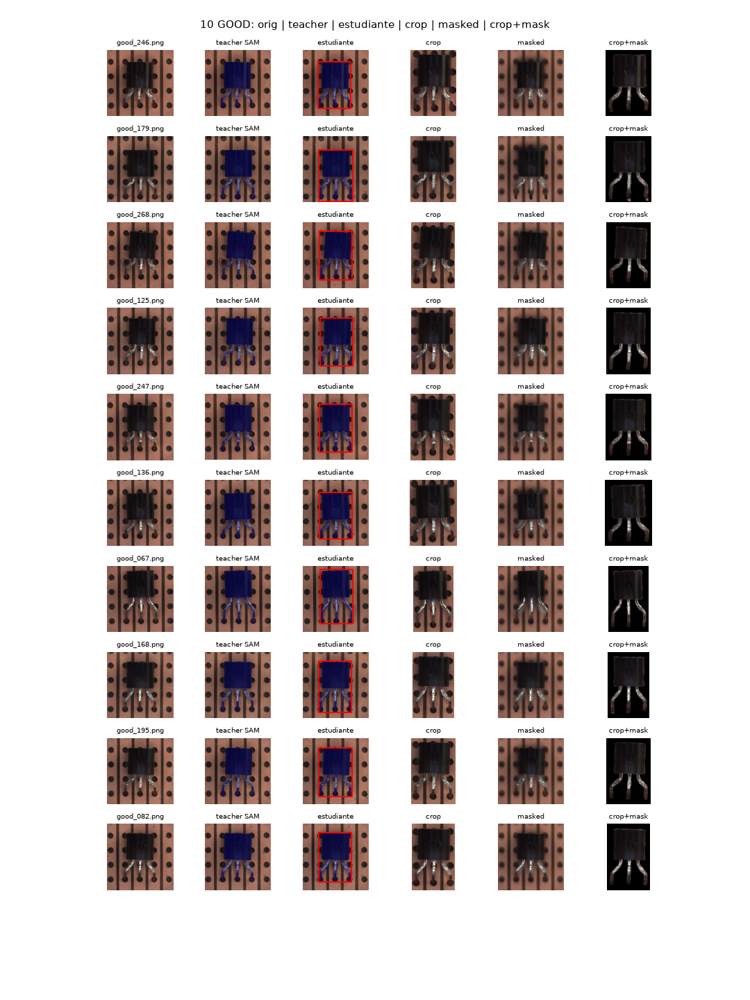
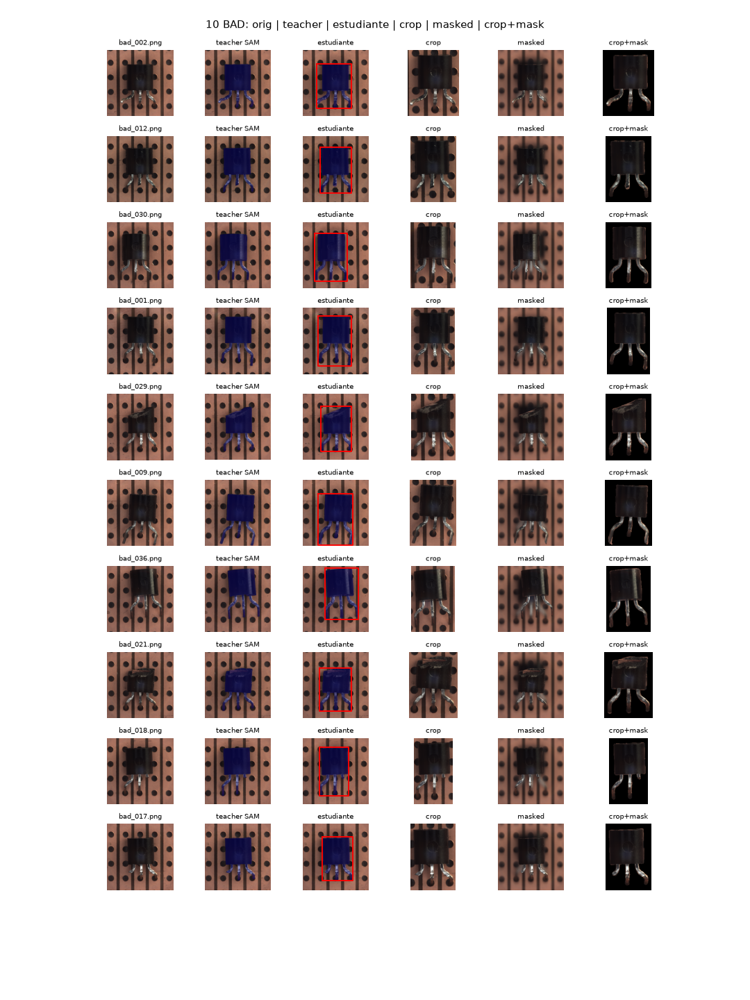

In [ ]:
# Proposito: 2 mosaicos (10 GOOD y 10 BAD): original | teacher | estudiante | crop | masked | crop+mask.
# Lee mascaras de cache (SAM ya esta descargado desde §1): solo muestra, no segmenta.
mo.stop(CAPTURE_MODE, mo.md("figura omitida en modo captura"))
tic('viz_crops')
_pos_all = {f: i for i, f in enumerate(sam_masks.filename)}

def _mosaico(_rows, _titulo, _fname, _idx):
    _f, _axs = plt.subplots(len(_rows), 6, figsize=(12, 1.6 * len(_rows)))
    _f.patch.set_facecolor("white")
    for _k, _r in enumerate(_rows):
        _im = Image.open(_r.path).convert("RGB")
        _tm = np.array(Image.open(teacher_mask_dir / _r.filename)) > 127
        _sm = np.array(Image.fromarray((sam_masks256[_idx[_r.filename]].numpy() * 255).astype("uint8")).resize(_im.size)) > 0
        _bb = mask_to_bbox(_sm)
        _row = _axs[_k] if len(_rows) > 1 else _axs
        _row[0].imshow(_im)
        _row[0].set_title(_r.filename, fontsize=8, color="black")
        _row[1].imshow(_im)
        _row[1].imshow(np.ma.masked_where(~_tm[::4, ::4], np.ones(_tm[::4, ::4].shape)), cmap="jet", alpha=0.4, extent=(0, _im.size[0], _im.size[1], 0))
        _row[1].set_title("teacher SAM", fontsize=8, color="black")
        _row[2].imshow(_im)
        _row[2].imshow(np.ma.masked_where(~_sm[::4, ::4], np.ones(_sm[::4, ::4].shape)), cmap="jet", alpha=0.4, extent=(0, _im.size[0], _im.size[1], 0))
        if _bb:
            _x0, _y0, _x1, _y1 = _bb
            _row[2].plot([_x0, _x1, _x1, _x0, _x0], [_y0, _y0, _y1, _y1, _y0], "r-")
        _row[2].set_title("estudiante", fontsize=8, color="black")
        _row[3].imshow(variant_image(_r.filename, _r.path, "crop"))
        _row[3].set_title("crop", fontsize=8, color="black")
        _row[4].imshow(variant_image(_r.filename, _r.path, "masked"))
        _row[4].set_title("masked", fontsize=8, color="black")
        _full = np.array(Image.fromarray((_sm * 255).astype("uint8")).resize((1024, 1024))) > 0
        _cropmask = Image.fromarray(np.where(_full[:, :, None], np.asarray(_im.resize((1024, 1024))), np.zeros((1024, 1024, 3), np.uint8))).crop(expand_bbox(_bb, (1024, 1024), SAM_PADDING)) if _bb else _im
        _row[5].imshow(_cropmask)
        _row[5].set_title("crop+mask", fontsize=8, color="black")
        [a.axis("off") for a in _row]
    _f.suptitle(_titulo, fontsize=12, color="black")
    _f.subplots_adjust(wspace=0.05, hspace=0.3, top=0.95)
    _f.savefig(FIG_DIR / _fname, dpi=90)
    print("saved", _fname)
    return _f

_goods = list(train_files[train_files.label == "good"].itertuples())[:10]
_bads = list(train_files[train_files.label == "bad"].itertuples())[:10]
_fg = _mosaico(_goods, "10 GOOD: orig | teacher | estudiante | crop | masked | crop+mask", "ejemplos_good.png", _pos_all)
_fb = _mosaico(_bads, "10 BAD: orig | teacher | estudiante | crop | masked | crop+mask", "ejemplos_bad.png", _pos_all)
toc('viz_crops')
# Los Figure con 120 paneles de 1024px pesan 8.7 MB y marimo los rechaza:
# se muestran los PNG ya guardados (0.8 MB cada uno).
mo.vstack([mo.image(str(FIG_DIR / "ejemplos_good.png")),
           mo.image(str(FIG_DIR / "ejemplos_bad.png"))])

### §3 DINO en la variante elegida + LogReg + export ONNX

In [ ]:
# §3 Proposito: embeddings CLS DINOv2 de la variante DINO_VARIANT (cache por fingerprint).

tic("dino_embed")

_ck = MODELS_DIR / f"dino_{DINO_VARIANT}.pt"
_stud_sha = hashlib.sha256(student_ckpt.read_bytes()).hexdigest()[:16]  # los embeddings dependen de las mascaras: sin esto se reutilizarian tras re-destilar
_dpok = False
if _ck.exists():
    _dpm = torch.load(_ck, map_location="cpu", weights_only=False)
    _dpok = _dpm.get("fingerprint") == fingerprint and _dpm.get("stud_sha") == _stud_sha and _dpm.get("variant") == DINO_VARIANT
    del _dpm
if _dpok:
    _dp = torch.load(_ck, map_location="cpu", weights_only=False)
    dino_X, dino_fnames = _dp["X"], _dp["fnames"]
    print("dino cache hit:", dino_X.shape, "(ckpt %s)" % _stud_sha)
else:
    _proc = AutoImageProcessor.from_pretrained(BACKBONE_ID)
    _model = AutoModel.from_pretrained(BACKBONE_ID).eval()
    for _pp in _model.parameters():
        _pp.requires_grad_(False)
    _dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    _model.to(_dev)
    _xs, _fn = [], []
    for _k, _r in enumerate(df_files.itertuples()):
        _ci = variant_image(_r.filename, _r.path, DINO_VARIANT)
        _in = _proc(images=_ci, size={"height": 224, "width": 224}, return_tensors="pt")
        with torch.inference_mode():
            _xs.append(_model(**{k: v.to(_dev) for k, v in _in.items()}).last_hidden_state[:, 0, :].cpu())
        _fn.append(_r.filename)
        if (_k + 1) % 50 == 0:
            print(f"dino {_k + 1}/{len(df_files)}", flush=True)
    import numpy as _np

    dino_X, dino_fnames = _np.concatenate([x.numpy() for x in _xs]), _fn
    torch.save({"X": dino_X, "fnames": dino_fnames, "fingerprint": fingerprint, "stud_sha": _stud_sha, "variant": DINO_VARIANT}, _ck)
    print("saved", dino_X.shape)
toc("dino_embed")
try:
    _model.to("cpu")
    print("DINO descargado")
except NameError:
    print("DINO ya estaba descargado (cache hit)")
import gc as _gc
_gc.collect()
torch.cuda.empty_cache()
print("DINO descargado, VRAM:", round(torch.cuda.memory_allocated() / 1e9, 2), "GB")

[04:42:30] inicio dino_embed
dino cache hit: (313, 768) (ckpt eef17457d57b7d83)
[04:42:31] fin dino_embed (0.2s)
DINO ya estaba descargado (cache hit)
DINO descargado, VRAM: 0.0 GB


In [ ]:
# §3 Proposito: LogReg en train, metricas en test, scores y export a ONNX.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report as _crN, roc_auc_score as _aucN

tic("dino_train")
_y_all = (df_files.set_index("filename").loc[dino_fnames, "label"] == "bad").to_numpy(int)
_pos = {f: i for i, f in enumerate(dino_fnames)}
_tri = [_pos[f] for f in train_files.filename]
_tei = [_pos[f] for f in test_files.filename]
_clf = LogisticRegression(class_weight="balanced", C=1.0, max_iter=2000).fit(dino_X[_tri], _y_all[_tri])
dino_scores = _clf.predict_proba(dino_X)[:, 1]
_cut = float(np.quantile(dino_scores[_tri][_y_all[_tri] == 0], 0.95))
_pr = (dino_scores[_tei] >= _cut).astype(int)
_yte = _y_all[_tei]
print(_crN(_yte, _pr, target_names=["good", "bad"], zero_division=0))
print(f"dino-test: auroc={_aucN(_yte, dino_scores[_tei]):.4f} cut={_cut:.3f}")
dino_npz = MODELS_DIR / "dino.npz"  # idem: las celdas que lo leen dependen de esta variable
np.savez(dino_npz, fnames=np.array(dino_fnames), y=_y_all, scores=dino_scores,
         train_idx=np.array(_tri), test_idx=np.array(_tei), cut=_cut)
from skl2onnx import to_onnx
from skl2onnx.common.data_types import FloatTensorType

_onnx = to_onnx(_clf, initial_types=[("input", FloatTensorType([None, dino_X.shape[1]]))], options={"zipmap": False})
(MODELS_DIR / "dino_logreg.onnx").write_bytes(_onnx.SerializeToString())
print("saved dino.npz + dino_logreg.onnx")
toc("dino_train")

[04:42:31] inicio dino_train
              precision    recall  f1-score   support

        good       0.98      0.87      0.92        55
         bad       0.50      0.88      0.64         8

    accuracy                           0.87        63
   macro avg       0.74      0.87      0.78        63
weighted avg       0.92      0.87      0.89        63

dino-test: auroc=0.9727 cut=0.046
saved dino.npz + dino_logreg.onnx
[04:42:31] fin dino_train (0.4s)


[04:42:31] inicio tsne
tsne listo: (313, 2)
saved tsne_dino.png
[04:42:32] fin tsne (0.8s)



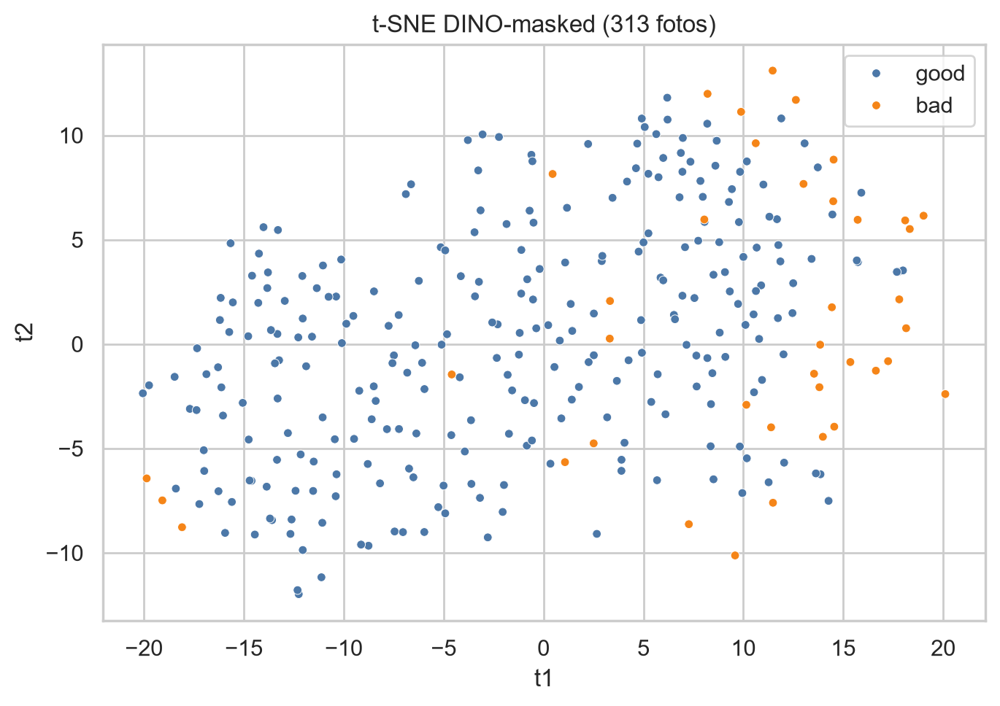

In [ ]:
# Proposito: t-SNE de embeddings DINO (separacion GOOD/BAD de un vistazo). Solo visualiza.
mo.stop(CAPTURE_MODE, mo.md("figura omitida en modo captura"))
tic('tsne')
from sklearn.manifold import TSNE as _TSNE
_yy = (df_files.set_index("filename").loc[dino_fnames, "label"] == "bad").to_numpy(int)
_Z = _TSNE(n_components=2, perplexity=30, random_state=42, init="pca", learning_rate="auto").fit_transform(dino_X)
print("tsne listo:", _Z.shape, flush=True)
import seaborn as _snsT
_snsT.set_theme(style="whitegrid")
_ft, _at = plt.subplots(figsize=(7, 5))
_snsT.scatterplot(x=_Z[:, 0], y=_Z[:, 1], hue=["bad" if y else "good" for y in _yy], palette={"good": "#4C78A8", "bad": "#F58518"}, s=18, ax=_at)
_at.set(title=f't-SNE DINO-{DINO_VARIANT} ({len(dino_fnames)} fotos)', xlabel="t1", ylabel="t2")
_ft.tight_layout()
_ft.savefig(FIG_DIR / "tsne_dino.png", dpi=100)
print("saved tsne_dino.png")
toc('tsne')
mo.vstack([_ft])

[04:42:32] inicio cm_dino
dino-test: tn=48 fp=7 fn=1 tp=7
saved cm_dino.png
[04:42:32] fin cm_dino (0.1s)



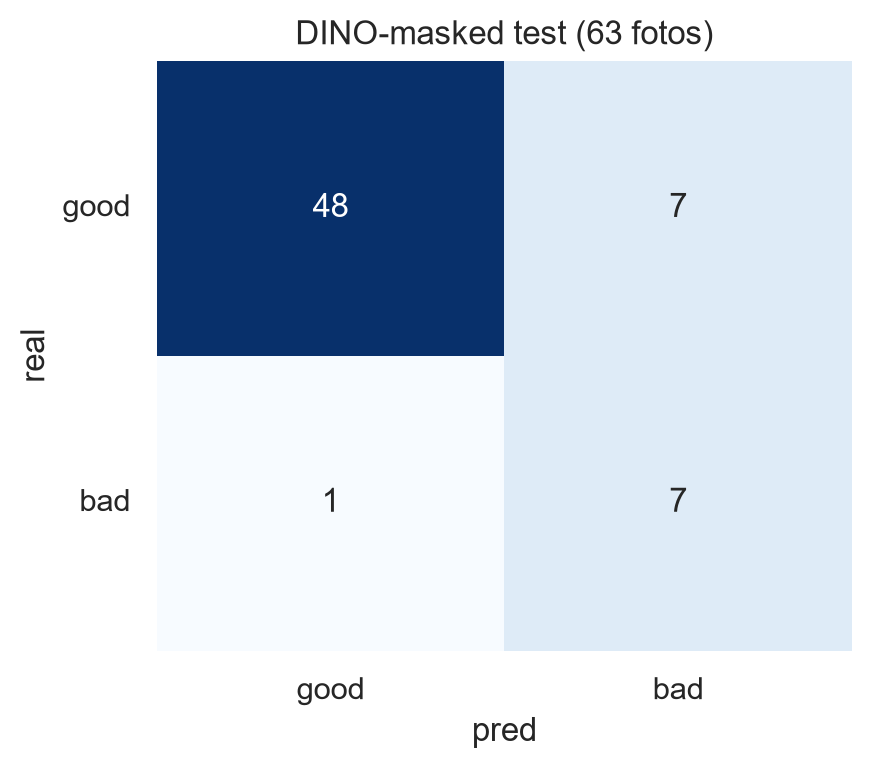

In [ ]:
# Proposito: matriz de confusion de DINO en test (EffAD/fusion llegan tras el entreno). Solo muestra.
mo.stop(CAPTURE_MODE, mo.md("figura omitida en modo captura"))
tic('cm_dino')
from sklearn.metrics import confusion_matrix as _cmx9
import seaborn as _sns9
_sns9.set_theme(style="whitegrid")
_dz = np.load(dino_npz)
_yte9 = _dz["y"][_dz["test_idx"]].astype(int)
_pr9 = (_dz["scores"][_dz["test_idx"]] >= float(_dz["cut"])).astype(int)
_tn, _fp, _fn, _tp = _cmx9(_yte9, _pr9).ravel()
print(f"dino-test: tn={_tn} fp={_fp} fn={_fn} tp={_tp}")
_fc9, _ac9 = plt.subplots(figsize=(4.5, 4))
_sns9.heatmap([[_tn, _fp], [_fn, _tp]], annot=True, fmt="d", cmap="Blues", cbar=False, ax=_ac9)
_ac9.set(title=f'DINO-{DINO_VARIANT} test ({len(_dz["test_idx"])} fotos)', xlabel="pred", ylabel="real")
_ac9.set_xticklabels(["good", "bad"])
_ac9.set_yticklabels(["good", "bad"], rotation=0)
_fc9.tight_layout()
_fc9.savefig(FIG_DIR / "cm_dino.png", dpi=100)
print("saved cm_dino.png")
toc('cm_dino')
mo.vstack([_fc9])

### §4 EffAD en original, 5000 steps con logs + export ONNX

In [ ]:
# §4 Proposito: entrena EfficientAD solo en GOOD-train (variante EFFAD_VARIANT) y exporta a ONNX.
import glob
import os  # elegir el ckpt por fecha, no por nombre

tic("effad_train")
from lightning.pytorch import seed_everything
from torch.utils.data import DataLoader
from lightning.pytorch import LightningDataModule
from anomalib.data.dataclasses.torch import ImageBatch
from anomalib.models import EfficientAd
from anomalib.engine import Engine

seed_everything(SEED)
_good_tr = train_files[train_files.label == "good"]

def _tensor(_path, _fn):
    _im = variant_image(_fn, _path, EFFAD_VARIANT).resize((256, 256))
    return torch.from_numpy(np.asarray(_im, dtype="float32") / 255.0).permute(2, 0, 1)

class _DM(LightningDataModule):
    def __init__(self, _t):
        super().__init__()
        self.train_batch_size = 1
        self.name = EFFAD_VARIANT
        self.category = EFFAD_VARIANT
        self._t = _t

    def train_dataloader(self):
        return DataLoader(self._t, batch_size=1, shuffle=True, collate_fn=lambda _b: ImageBatch(image=torch.stack(_b)))

from lightning.pytorch.callbacks import Callback as _CB
class _LogSteps(_CB):
    def on_train_batch_end(self, trainer, *_a, **_k):
        _gs = int(trainer.global_step)
        if _gs % 250 == 0 and _gs > 0:
            _mm = {k: float(v) for k, v in trainer.callback_metrics.items()}
            _msg = " ".join(k + "=" + format(v, ".4f") for k, v in _mm.items()) or "(sin metricas)"
            print("effad step %d/%d %s" % (_gs, STEPS, _msg), flush=True)
_model = EfficientAd(model_size=EFFAD_SIZE, visualizer=False, evaluator=False)
_eng = Engine(logger=True, default_root_dir=str(MODELS_DIR / "effad"), max_steps=STEPS, callbacks=[_LogSteps()])
print(f"entrenando EffAD-{EFFAD_SIZE} en {len(_good_tr)} GOOD x {STEPS} steps (log cada N steps en light_logs/)", flush=True)
print("callback cada 250 steps enganchado")
import glob as _gb2
_ckpts = sorted(_gb2.glob(str(MODELS_DIR / "effad/**/*.ckpt"), recursive=True), key=os.path.getmtime)
_resume = _ckpts[-1] if _ckpts else None
print("resume desde:", _resume, flush=True)
_eng.fit(model=_model, datamodule=_DM([_tensor(r.path, r.filename) for r in _good_tr.itertuples()]), ckpt_path=_resume)
_ckpt = sorted(glob.glob(str(MODELS_DIR / "effad/**/*.ckpt"), recursive=True), key=os.path.getmtime)[-1]
print("ckpt:", _ckpt)

# Export ONNX: wrapper que devuelve pred_score como tensor.
import torch.nn as _nn

class _EffWrap(_nn.Module):
    def __init__(self, _m):
        super().__init__()
        self._m = _m

    def forward(self, _x):
        return self._m(_x).pred_score

_model.eval()
_dummy = torch.zeros(1, 3, 256, 256)
torch.onnx.export(_EffWrap(_model).eval(), _dummy, str(MODELS_DIR / "effad.onnx"),
                  input_names=["input"], output_names=["score"], opset_version=17, dynamo=False)
print("saved effad.onnx")
del _model, _eng  # el Engine retiene el modelo en GPU si no se suelta
import gc as _gcE
_gcE.collect()
torch.cuda.empty_cache()
toc("effad_train")

[04:42:32] inicio effad_train


W1111 04:42:33.315000 26612 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
C:\Users\marti\Documents\BetterClasificator\.venv\Lib\site-packages\anomalib\models\image\dinomaly\components\layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention
2026/11/11 04:42:36 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at C:\Users\marti\Documents\BetterClasificator\.venv\Lib\site-packages\mlflow\assistant\skills\mlflow-trace-instrumentation\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.
Seed set to 42


entrenando EffAD-medium en 218 GOOD x 5000 steps (log cada N steps en light_logs/)
callback cada 250 steps enganchado
resume desde: models\transistor_binary\prod_sam31_distill\effad\EfficientAd\none\none\v0\weights\lightning\model.ckpt


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
C:\Users\marti\Documents\BetterClasificator\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\logger_connector\logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `lightning.pytorch` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
C:\Users\marti\Documents\BetterClasificator\.venv\Lib\site-packages\lightning\pytorch\trainer\configuration_validator.py:70: You defined a

+----------------------------------------------------------------+
|   | Name           | Type             | Params | Mode  | FLOPs |
|---+----------------+------------------+--------+-------+-------|
| 0 | pre_processor  | PreProcessor     |      0 | train |     0 |
| 1 | post_processor | PostProcessor    |      0 | train |     0 |
| 2 | model          | EfficientAdModel | 20.7 M | train |     0 |
+----------------------------------------------------------------+
Trainable params: 20.7 M                                                       
Non-trainable params: 0                                                        
Total params: 20.7 M                                                           
Total estimated model params size (MB): 82.957                                 
Modules in train mode: 43                                                      
Modules in eval mode: 9                                                        
Total FLOPs: 0                                     

Restored all states from the checkpoint at C:\Users\marti\Documents\BetterClasificator\models\transistor_binary\prod_sam31_distill\effad\EfficientAd\none\none\v0\weights\lightning\model.ckpt
C:\Users\marti\Documents\BetterClasificator\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
C:\Users\marti\Documents\BetterClasificator\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
`Trainer.fit` stopped: `max_steps=5000` reached.


ckpt: models\transistor_binary\prod_sam31_distill\effad\EfficientAd\none\none\v0\weights\lightning\model.ckpt


C:\Users\marti\AppData\Local\Temp\marimo_26612\__marimo__cell_ecfG_.py:64: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(_EffWrap(_model).eval(), _dummy, str(MODELS_DIR / "effad.onnx"),
C:\Users\marti\Documents\BetterClasificator\.venv\Lib\site-packages\torch\onnx\_internal\torchscript_exporter\jit_utils.py:308: UserWarning: Constant folding - Only steps=1 can be constant folded for opset >= 10 onnx::Slice op. Constant folding not applied. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\jit\passes\onnx\constant_fold.cpp:180.)
  _C._jit_pass_onnx_node_shape_type_inference(node, params_dict, opset_version

saved effad.onnx
[04:42:50] fin effad_train (18.1s)


### §5 Fusión dino + effad (alpha en train) y scores test

In [ ]:
# §5 Proposito: normaliza con train-GOOD, elige alpha en train, corta q95 y scorea test (dino+effad+fusion).

tic("fusion")

_y = (df_files.set_index("filename").loc[dino_fnames, "label"] == "bad").to_numpy(int)
_pos = {f: i for i, f in enumerate(dino_fnames)}
_tri = [_pos[f] for f in train_files.filename]
_tei = [_pos[f] for f in test_files.filename]
_ckpt = sorted(glob.glob(str(MODELS_DIR / "effad/**/*.ckpt"), recursive=True), key=os.path.getmtime)[-1]
_em = EfficientAd.load_from_checkpoint(_ckpt, map_location="cpu").eval()
_dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_em.to(_dev)
_es = []
with torch.inference_mode():
    for _s in range(0, len(dino_fnames), 16):
        _xb = torch.stack([torch.from_numpy(np.asarray(variant_image(f, df_files.set_index("filename").loc[f, "path"], "none").resize((256, 256)), dtype="float32") / 255.0).permute(2, 0, 1) for f in dino_fnames[_s:_s + 16]]).to(_dev)
        _es.extend(_em(_xb).pred_score.flatten().cpu().tolist())
        if (_s // 16 + 1) % 5 == 0:
            print(f"effad score {_s + 16}/{len(dino_fnames)}", flush=True)
effad_scores = np.array(_es)
_gd = [i for i in _tri if _y[i] == 0]
_md = float(np.median(dino_scores[_gd]))
_id = float(max(np.subtract(*np.percentile(dino_scores[_gd], [75, 25])), 1e-9))
_me = float(np.median(effad_scores[_gd]))
_ie = float(max(np.subtract(*np.percentile(effad_scores[_gd], [75, 25])), 1e-9))
_dtr, _etr = (dino_scores[_tri] - _md) / _id, (effad_scores[_tri] - _me) / _ie
_best = None
for _a in np.arange(0, 1.05, 0.05).round(2):
    _ftr = _a * _dtr + (1 - _a) * _etr
    _thr = float(np.quantile(_ftr[_y[_tri] == 0], 0.95))
    _pr = (_ftr >= _thr).astype(int)
    _rec = float((_pr[_y[_tri] == 1] == 1).mean())
    _far = float((_pr[_y[_tri] == 0] == 1).mean())
    if _best is None or (_rec, -_far) > (_best[1], -_best[2]):
        _best = (float(_a), _rec, _far, _thr)
_alpha, _, _, _cut = _best
fused_scores = _alpha * (dino_scores - _md) / _id + (1 - _alpha) * (effad_scores - _me) / _ie
fusion_npz = MODELS_DIR / "fusion.npz"  # nombre compartido: la arista §5->§6/§8 vive en el grafo, no en el disco
np.savez(fusion_npz, alpha=_alpha, cut=_cut, md=_md, id=_id, me=_me, ie=_ie,
         fnames=np.array(dino_fnames), y=_y, dino=dino_scores, effad=effad_scores, fused=fused_scores,
         train_idx=np.array(_tri), test_idx=np.array(_tei))
print(f"alpha={_alpha} cut={_cut:.3f} saved fusion.npz")
_em.to("cpu"); torch.cuda.empty_cache()
print("EffAD descargado")
toc("fusion")

[04:42:50] inicio fusion
effad score 80/313
effad score 160/313
effad score 240/313
effad score 320/313
alpha=0.05 cut=2.327 saved fusion.npz
EffAD descargado
[04:43:11] fin fusion (20.2s)


### §6 Evaluación: reportes, matrices, McNemar, bootstrap + figuras mostradas

[04:43:11] inicio eval
dino {'method': 'dino', 'auroc': 0.9727, 'recall': 0.875, 'far': 0.127, 'prec_bad': 0.5, 'f1_bad': 0.636}
effad {'method': 'effad', 'auroc': 0.9818, 'recall': 0.875, 'far': 0.055, 'prec_bad': 0.7, 'f1_bad': 0.778}
fused {'method': 'fused', 'auroc': 0.9955, 'recall': 1.0, 'far': 0.091, 'prec_bad': 0.615, 'f1_bad': 0.762}
McNemar: {('dino', 'effad'): 0.3438, ('dino', 'fused'): 0.4531, ('effad', 'fused'): 1.0}
saved eval.csv, recall.png, cm.png
[04:43:11] fin eval (0.4s)



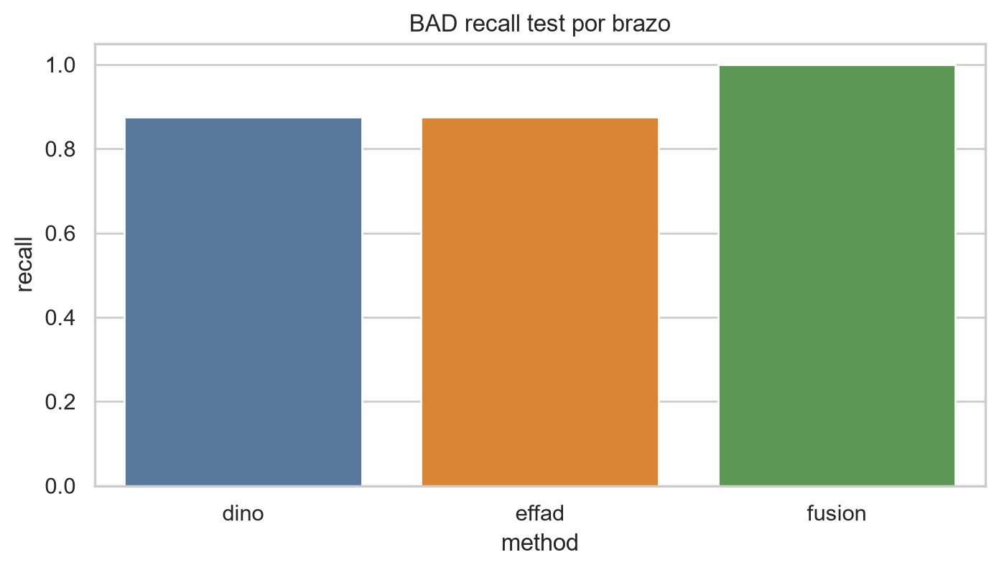
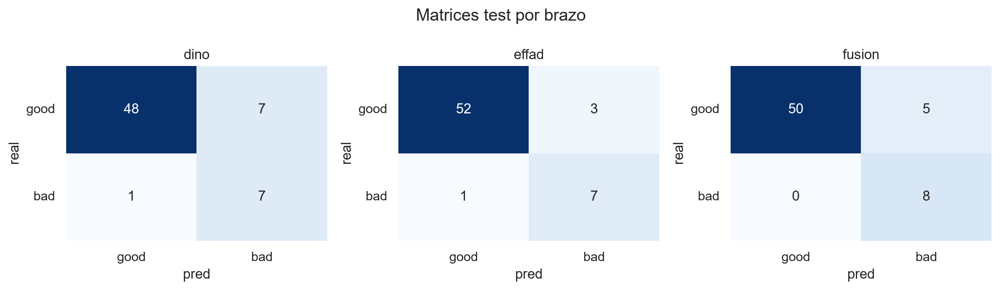

In [ ]:
# §6 Proposito: metricas test por brazo + figuras seaborn (barras + matrices + McNemar). Sin hardcodes.
tic("eval")
import seaborn as sns
from sklearn.metrics import classification_report as _cr6, confusion_matrix as _cmx6, roc_auc_score as _auc6
sns.set_theme(style="whitegrid")
_fz = np.load(fusion_npz)
_y = _fz["y"].astype(int)
_te = _fz["test_idx"]
_yte = _y[_te]
_pal = {"dino": "#4C78A8", "effad": "#F58518", "fusion": "#54A24B"}
_rows, _preds = [], {}
for _m in ("dino", "effad", "fused"):
    _sc = _fz[{"dino": "dino", "effad": "effad", "fused": "fused"}[_m]]
    _cut = float(np.quantile(_sc[_fz["train_idx"]][_y[_fz["train_idx"]] == 0], 0.95))
    _pr = (_sc[_te] >= _cut).astype(int)
    _preds[_m] = _pr
    _rep = _cr6(_yte, _pr, target_names=["good", "bad"], output_dict=True, zero_division=0)
    _rows.append({"method": _m, "auroc": round(float(_auc6(_yte, _sc[_te])), 4), "recall": round(float(_rep["bad"]["recall"]), 3), "far": round(float((_pr[_yte == 0] == 1).mean()), 3), "prec_bad": round(float(_rep["bad"]["precision"]), 3), "f1_bad": round(float(_rep["bad"]["f1-score"]), 3)})
    print(_m, _rows[-1], flush=True)
eval_df = pd.DataFrame(_rows)
eval_df.to_csv(MODELS_DIR / "eval.csv", index=False)
_mlab = ["dino", "effad", "fusion"]
import math as _m6
def _mcn6(_a, _b):
    # McNemar sobre acierto/error vs etiqueta real (b = A-falla B-acierta, c = A-acierta B-falla).
    _caa, _cbb = (_a == _yte), (_b == _yte)
    _n01 = int(((_caa == 0) & (_cbb == 1)).sum())
    _n10 = int(((_caa == 1) & (_cbb == 0)).sum())
    _n = _n01 + _n10
    return 1.0 if _n == 0 else round(min(1.0, 2.0 * sum(_m6.comb(_n, _k) for _k in range(0, min(_n01, _n10) + 1)) / 2.0 ** _n), 4)
print("McNemar:", {p: _mcn6(_preds[p[0]], _preds[p[1]]) for p in [("dino", "effad"), ("dino", "fused"), ("effad", "fused")]}, flush=True)
_fe, _ae = plt.subplots(figsize=(8, 4))
sns.barplot(data=pd.DataFrame({"method": _mlab, "recall": [r["recall"] for r in _rows]}), x="method", y="recall", hue="method", legend=False, palette=_pal, ax=_ae, order=_mlab)
_ae.set(title="BAD recall test por brazo", ylim=(0, 1.05))
_fm, _am = plt.subplots(1, 3, figsize=(12, 3.5))
for _ax, _m in zip(_am, _mlab):
    _tn, _fp, _fn, _tp = _cmx6(_yte, _preds[{"dino": "dino", "effad": "effad", "fusion": "fused"}[_m]]).ravel()
    sns.heatmap([[_tn, _fp], [_fn, _tp]], annot=True, fmt="d", cmap="Blues", cbar=False, ax=_ax)
    _ax.set(title=_m, xlabel="pred", ylabel="real")
    _ax.set_xticklabels(["good", "bad"])
    _ax.set_yticklabels(["good", "bad"], rotation=0)
_fm.suptitle("Matrices test por brazo")
_fm.tight_layout()
FIG_DIR.mkdir(parents=True, exist_ok=True)
_fe.savefig(FIG_DIR / "recall.png", dpi=100)
_fm.savefig(FIG_DIR / "cm.png", dpi=100)
print("saved eval.csv, recall.png, cm.png")
toc("eval")
mo.vstack([_fe, _fm])

[04:43:11] inicio explain
ckpt: models\transistor_binary\prod_sam31_distill\effad\EfficientAd\none\none\v0\weights\lightning\model.ckpt
explain 4/8
explain 8/8
saved explain_effad.png
[04:43:13] fin explain (1.9s)



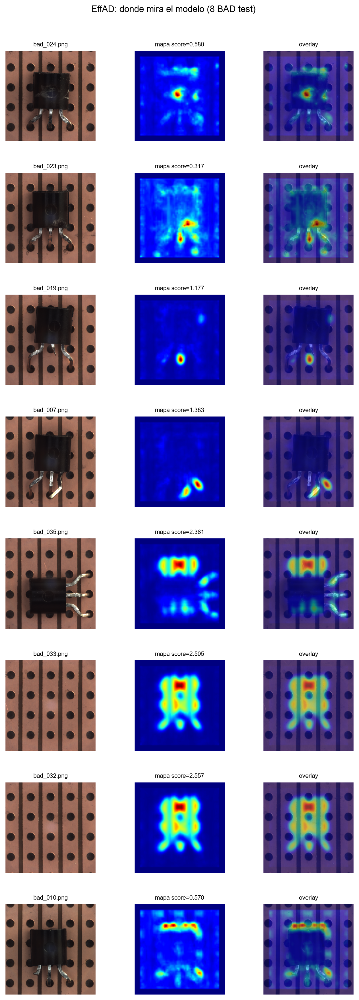

In [ ]:
# Proposito: explicabilidad EffAD (mapa de anomalia sobre las BAD de test). Solo muestra.
mo.stop(CAPTURE_MODE, mo.md("figura omitida en modo captura"))
tic("explain")
import glob as _gb9
from anomalib.models import EfficientAd as _EA9
_ckpt9 = sorted(_gb9.glob(str(MODELS_DIR / "effad/**/*.ckpt"), recursive=True), key=os.path.getmtime)[-1]
_em9 = _EA9.load_from_checkpoint(_ckpt9, map_location="cpu").eval()
_dev9 = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_em9.to(_dev9)
print("ckpt:", _ckpt9, flush=True)
_bads9 = test_files[test_files.label == "bad"].itertuples()
_blist = list(_bads9)
_fx, _axx = plt.subplots(len(_blist), 3, figsize=(9, 2.6 * len(_blist)))
_fx.patch.set_facecolor("white")
for _k, _r in enumerate(_blist):
    _im0 = Image.open(_r.path).convert("RGB")
    _xb = torch.from_numpy(np.asarray(_im0.resize((256, 256)), dtype="float32") / 255.0).permute(2, 0, 1).unsqueeze(0).to(_dev9)
    with torch.inference_mode():
        _out = _em9(_xb)
        _amap = _out.anomaly_map.squeeze().cpu().numpy()
        _sc = float(_out.pred_score.flatten()[0])
    _row = _axx[_k] if len(_blist) > 1 else _axx
    _row[0].imshow(_im0)
    _row[0].set_title(_r.filename, fontsize=8, color="black")
    _row[1].imshow(_amap, cmap="jet")
    _row[1].set_title(f"mapa score={_sc:.3f}", fontsize=8, color="black")
    _row[2].imshow(_im0.resize((256, 256)))
    _row[2].imshow(_amap, cmap="jet", alpha=0.5)
    _row[2].set_title("overlay", fontsize=8, color="black")
    [a.axis("off") for a in _row]
    if (_k + 1) % 4 == 0:
        print(f"explain {_k + 1}/{len(_blist)}", flush=True)
_fx.suptitle("EffAD: donde mira el modelo (8 BAD test)", fontsize=12, color="black")
_fx.subplots_adjust(wspace=0.05, hspace=0.35, top=0.94)
_fx.savefig(FIG_DIR / "explain_effad.png", dpi=90)
print("saved explain_effad.png")
_em9.to("cpu"); torch.cuda.empty_cache()
toc("explain")
mo.vstack([_fx])

[04:43:15] inicio explain_dino
saved explain_dino.png
[04:43:18] fin explain_dino (2.6s)



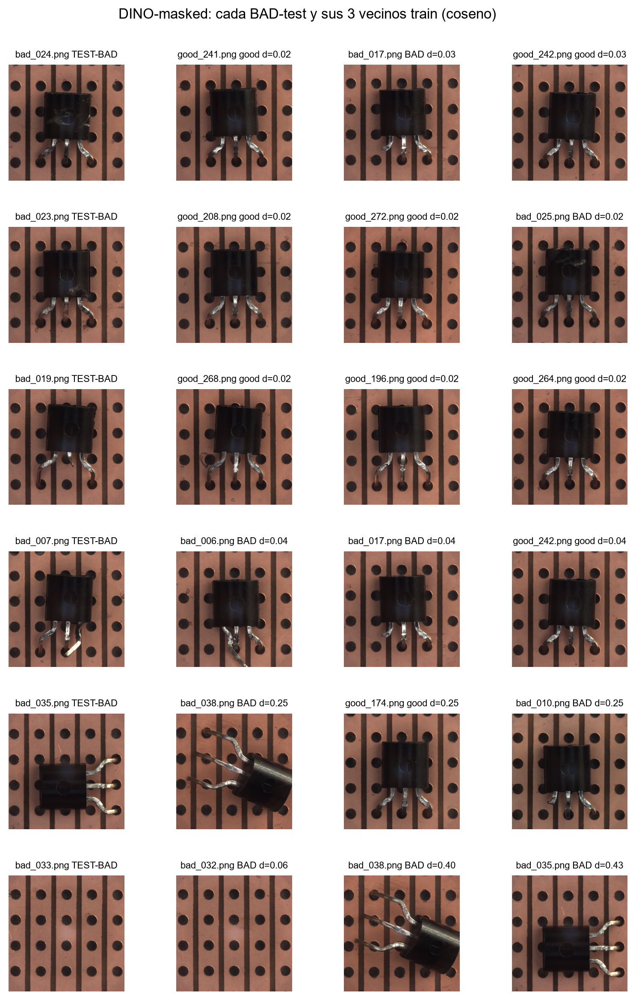

In [ ]:
# Proposito: explicabilidad DINO por vecinos cercanos (por que decidio BAD: a que trains se parece). Solo muestra.
mo.stop(CAPTURE_MODE, mo.md("figura omitida en modo captura"))
tic("explain_dino")
_dz9 = np.load(dino_npz)
_X9 = torch.load(MODELS_DIR / f"dino_{DINO_VARIANT}.pt", map_location="cpu", weights_only=False)["X"]
_fn9 = list(_dz9["fnames"])
_te9 = list(_dz9["test_idx"])
_laball = (df_files.set_index("filename").loc[_fn9, "label"] == "bad").to_numpy(int)
_pathof = dict(zip(df_files.filename, df_files.path))
_bad_te = [i for i in _te9 if _laball[i] == 1][:6]
_Xn = _X9 / np.linalg.norm(_X9, axis=1, keepdims=True)
_fx9, _axx9 = plt.subplots(len(_bad_te), 4, figsize=(10, 2.2 * len(_bad_te)))
_fx9.patch.set_facecolor("white")
for _k, _i in enumerate(_bad_te):
    _d = 1 - _Xn[_i] @ _Xn.T
    _d[_i] = 9
    _nn = np.argsort(_d)[:3]
    _row = _axx9[_k] if len(_bad_te) > 1 else _axx9
    _row[0].imshow(Image.open(_pathof[_fn9[_i]]).convert("RGB"))
    _row[0].set_title(_fn9[_i] + " TEST-BAD", fontsize=8, color="black")
    for _j, _n in enumerate(_nn):
        _tag = "BAD" if _laball[_n] else "good"
        _row[_j + 1].imshow(Image.open(_pathof[_fn9[_n]]).convert("RGB"))
        _row[_j + 1].set_title(_fn9[_n] + " " + _tag + " d=" + format(float(_d[_n]), ".2f"), fontsize=8, color="black")
    [a.axis("off") for a in _row]
_fx9.suptitle(f"DINO-{DINO_VARIANT}: cada BAD-test y sus 3 vecinos train (coseno)", fontsize=12, color="black")
_fx9.subplots_adjust(wspace=0.05, hspace=0.4, top=0.93)
_fx9.savefig(FIG_DIR / "explain_dino.png", dpi=90)
print("saved explain_dino.png")
toc("explain_dino")
mo.vstack([_fx9])

[04:43:21] inicio figs_dist
cortes: {'dino': 0.046, 'effad': 0.363, 'fusion': 2.327}
saved dist_scores.png
saved roc.png
saved strip_dino.png
saved scatter_arms.png
[04:43:22] fin figs_dist (0.7s)



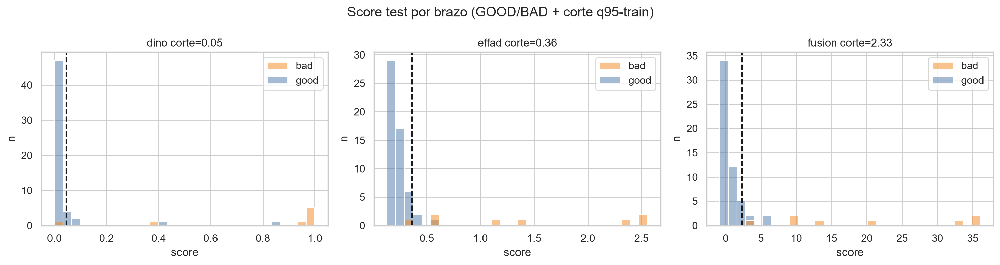
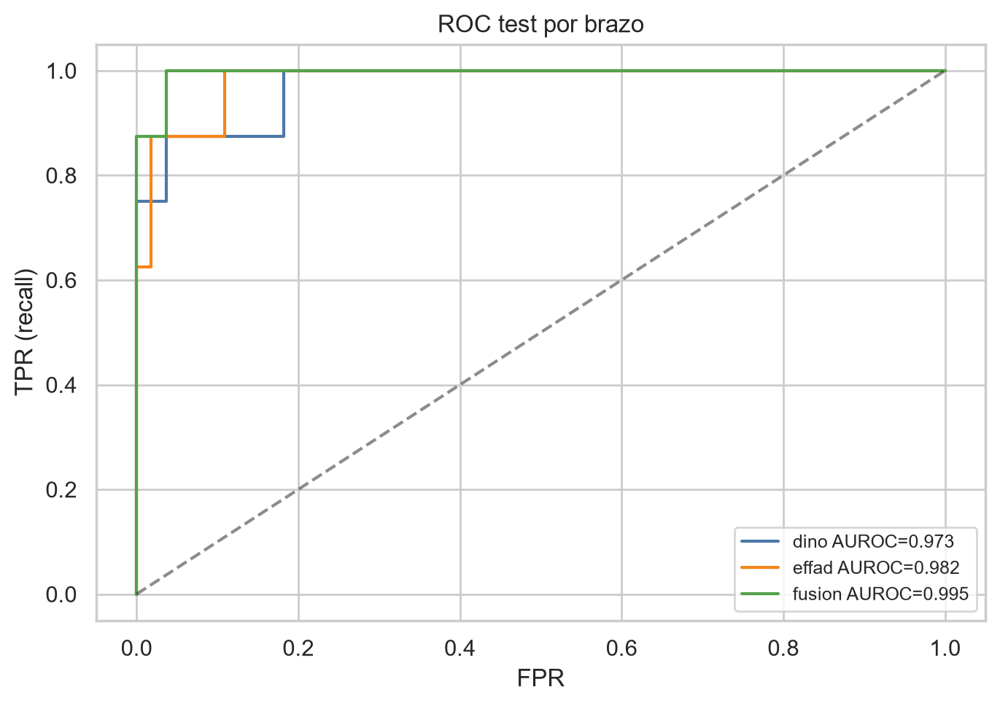
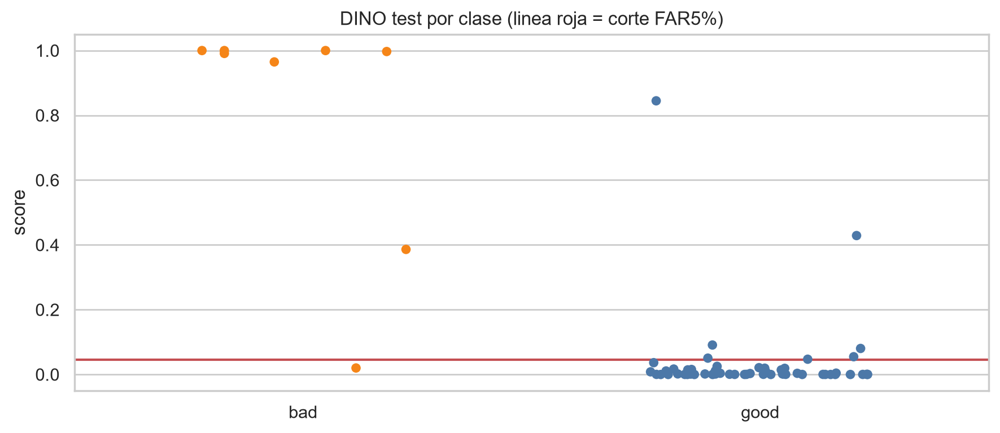
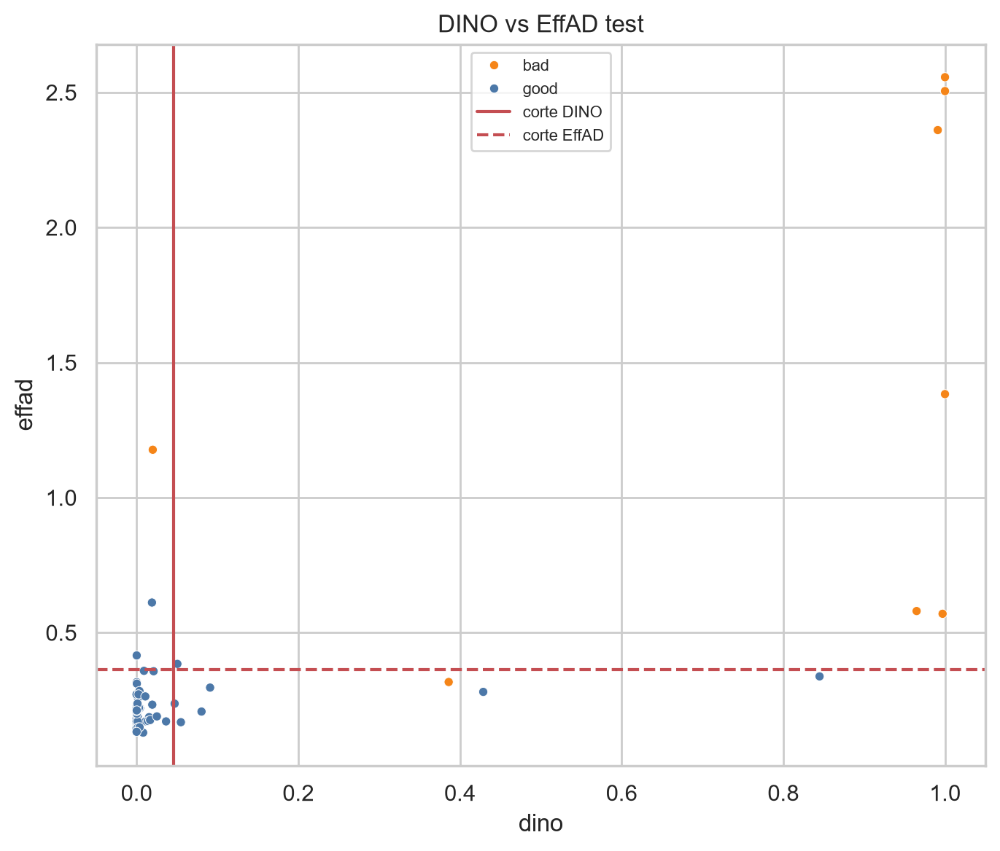

In [ ]:
# Proposito: 4 figuras diagnosticas test (distribuciones, ROC, strip por clase, scatter dino-vs-effad). Solo muestra.
mo.stop(CAPTURE_MODE, mo.md("figura omitida en modo captura"))
tic("figs_dist")
import seaborn as _snsD
from sklearn.metrics import roc_curve as _rcc, roc_auc_score as _au9
_snsD.set_theme(style="whitegrid")
_fz9 = np.load(fusion_npz)
_y9 = _fz9["y"].astype(int)
_tr9, _te9 = _fz9["train_idx"], _fz9["test_idx"]
_S9 = {"dino": _fz9["dino"], "effad": _fz9["effad"], "fusion": _fz9["fused"]}
_cuts9 = {m: float(np.quantile(_S9[m][_tr9][_y9[_tr9] == 0], 0.95)) for m in _S9}
print("cortes:", {m: round(c, 3) for m, c in _cuts9.items()}, flush=True)
_lab9 = np.array(["bad" if y else "good" for y in _y9[_te9]])
_f1, _a1 = plt.subplots(1, 3, figsize=(15, 4))
for _ax, _m in zip(_a1, ["dino", "effad", "fusion"]):
    _snsD.histplot(x=_S9[_m][_te9], hue=_lab9, palette={"good": "#4C78A8", "bad": "#F58518"}, bins=30, ax=_ax)
    _ax.axvline(_cuts9[_m], color="k", ls="--")
    _ax.set(title=_m + " corte=" + format(_cuts9[_m], ".2f"), xlabel="score", ylabel="n")
_f1.suptitle("Score test por brazo (GOOD/BAD + corte q95-train)")
_f1.tight_layout()
_f1.savefig(FIG_DIR / "dist_scores.png", dpi=100)
print("saved dist_scores.png", flush=True)
_f2, _a2 = plt.subplots(figsize=(7, 5))
for _m, _c in [("dino", "#4C78A8"), ("effad", "#F58518"), ("fusion", "#54A24B")]:
    _fpr, _tpr, _ = _rcc(_y9[_te9], _S9[_m][_te9])
    _a2.plot(_fpr, _tpr, color=_c, label=_m + " AUROC=" + format(_au9(_y9[_te9], _S9[_m][_te9]), ".3f"))
_a2.plot([0, 1], [0, 1], "k--", alpha=0.5)
_a2.set(title="ROC test por brazo", xlabel="FPR", ylabel="TPR (recall)")
_a2.legend(fontsize=9)
_f2.tight_layout()
_f2.savefig(FIG_DIR / "roc.png", dpi=100)
print("saved roc.png", flush=True)
_f3, _a3 = plt.subplots(figsize=(9, 4))
_snsD.stripplot(x=_lab9, y=_S9["dino"][_te9], hue=_lab9, palette={"good": "#4C78A8", "bad": "#F58518"}, legend=False, s=6, jitter=0.25, ax=_a3)
_a3.axhline(_cuts9["dino"], color="r")
_a3.set(title="DINO test por clase (linea roja = corte FAR5%)", ylabel="score")
_f3.tight_layout()
_f3.savefig(FIG_DIR / "strip_dino.png", dpi=100)
print("saved strip_dino.png", flush=True)
_f4, _a4 = plt.subplots(figsize=(7, 6))
_snsD.scatterplot(x=_S9["dino"][_te9], y=_S9["effad"][_te9], hue=_lab9, palette={"good": "#4C78A8", "bad": "#F58518"}, s=20, ax=_a4)
_a4.axvline(_cuts9["dino"], color="r", label="corte DINO")
_a4.axhline(_cuts9["effad"], color="r", ls="--", label="corte EffAD")
_a4.set(title="DINO vs EffAD test", xlabel="dino", ylabel="effad")
_a4.legend(fontsize=8)
_f4.tight_layout()
_f4.savefig(FIG_DIR / "scatter_arms.png", dpi=100)
print("saved scatter_arms.png")
toc("figs_dist")
mo.vstack([_f1, _f2, _f3, _f4])

### §7 MLflow: params, métricas, ONNXs, figuras y fingerprint en un run

In [ ]:
# §7 Proposito: deja todo trazado en MLflow (reproducible por fingerprint), estudiante incluido.
mo.stop(CAPTURE_MODE, mo.md("MLflow omitido en modo captura: no duplicar runs."))
tic("mlflow_final")

import mlflow

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(MLFLOW_EXPERIMENT)
with mlflow.start_run(run_name=f"{PROJECT_NAME}_prod_sam31_distill"):
    mlflow.log_params({"backbone": BACKBONE_ID, "dino_variant": DINO_VARIANT, "effad_variant": EFFAD_VARIANT,
                        "effad_size": EFFAD_SIZE, "steps": STEPS, "seed": SEED, "fingerprint": fingerprint,
                        "segmenter": EVIT_NAME, "segmenter_precision": "fp32", "segmenter_side": EVIT_SIDE,
                        "distill_epochs": EVIT_EPOCHS, "distill_batch": EVIT_BATCH, "distill_lr": EVIT_LR,
                        "distill_target": "teacher_binary_mask", "distill_prompt": "fixed_full_frame_1024"})
    for _, _r in eval_df.iterrows():
        mlflow.log_metrics({f"{_r.method}_recall": _r.recall, f"{_r.method}_far": _r.far, f"{_r.method}_auroc": _r.auroc})
    # Calidad del estudiante = acuerdo con el teacher, no exactitud humana.
    mlflow.log_metrics({"student_iou": float(student_quality.iou.mean()),
                        "student_dice": float(student_quality.dice.mean()),
                        "student_boundary_f1": float(student_quality.boundary_f1.mean()),
                        "student_empty_rate": float(student_quality.empty_mask.mean()),
                        **{"student_" + _k: float(_v) for _k, _v in student_speed.items() if isinstance(_v, (int, float))}})
    for _, _e in distill_log.iterrows():
        mlflow.log_metrics({"distill_train_loss": float(_e.train_loss), "distill_val_loss": float(_e.val_loss),
                            "distill_train_dice": float(_e.train_dice), "distill_val_dice": float(_e.val_dice)},
                           step=int(_e.epoch) - 1)
    for _f in ["dino.npz", "fusion.npz", "eval.csv", "dino_logreg.onnx", "effad.onnx", "good_mean.npy",
               "student/best.pt", "student/light_logs.csv", "student/quality.csv", "student/speed.json",
               "student/masks.csv", "teacher/masks.csv"]:
        mlflow.log_artifact(str(MODELS_DIR / _f))
    for _g in FIG_DIR.glob("*.png"):
        mlflow.log_artifact(str(_g))
    mlflow.set_tag("fingerprint", fingerprint)
    mlflow.set_tag("segmenter", EVIT_NAME)
print("mlflow listo")
toc("mlflow_final")

[04:43:22] inicio mlflow_final
mlflow listo
[04:43:25] fin mlflow_final (2.1s)


### §8 Inferencia end-to-end con el estudiante (sin SAM) — runtime único reutilizado por §9-§12
EffAD corre desde el checkpoint PyTorch en GPU: el ONNX-CPU por defecto costaba 3.77 s por frame
(y 126 s con denormales) en `industrial_profile.py`. Los dos caminos ONNX quedan disponibles para
que el §10 lo demuestre, pero la ruta de producción es GPU.

In [ ]:
# §8 Proposito: UNICA implementacion de la inferencia de produccion, reutilizada por §9-§12.
# collect=True sincroniza cada etapa (diagnostico); el benchmark del §10 usa collect=False y nvtx=False.
import contextlib as _ctx8
import time as _time8

import onnxruntime as _ort

try:  # al re-ejecutar esta celda se crean modelos nuevos en GPU: libera primero los anteriores,
    release_runtime()  # si no, cada re-run deja una generacion colgada (medido: 537 MB)
except NameError:
    pass
tic("runtime")
_dev8 = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_fz8 = np.load(fusion_npz)
_mean8 = np.load(good_mean_npy)  # misma media GOOD-train que el batch
_sess_logreg = _ort.InferenceSession(str(MODELS_DIR / "dino_logreg.onnx"))
# Tres caminos de EffAD: GPU (produccion) y los dos ONNX-CPU que el §10 compara.
_effad_ckpt8 = sorted(glob.glob(str(MODELS_DIR / "effad/**/*.ckpt"), recursive=True), key=os.path.getmtime)[-1]
_effad_gpu = EfficientAd.load_from_checkpoint(_effad_ckpt8, map_location="cpu").eval().to(_dev8)
_sess_effad = _ort.InferenceSession(str(MODELS_DIR / "effad.onnx"))
_opt_ftz = _ort.SessionOptions()
_opt_ftz.intra_op_num_threads = 4  # 4 hilos: elegido en la matriz 1/2/4 de industrial_profile.py
_sess_effad_ftz = _ort.InferenceSession(str(MODELS_DIR / "effad.onnx"), sess_options=_opt_ftz)
_proc8 = AutoImageProcessor.from_pretrained(BACKBONE_ID)
_dino8 = AutoModel.from_pretrained(BACKBONE_ID).eval().to(_dev8)
_student8 = load_student(student_ckpt).to(_dev8).float().eval()
print(f"runtime: estudiante {EVIT_SIDE}px + dinov2 + effad-{EFFAD_SIZE} en {_dev8}; ckpt {_effad_ckpt8}")

@_ctx8.contextmanager
def _stage(name, records, collect=False, nvtx=False):
    if collect:
        torch.cuda.synchronize()
        _t0 = _time8.perf_counter()
    with nvtx_range(name, nvtx):
        yield
        if collect:
            torch.cuda.synchronize()
    if collect:
        records[name] = (_time8.perf_counter() - _t0) * 1000

def infer(path, collect=False, nvtx=False, effad="gpu"):
    """Pipeline de produccion: estudiante -> mascara -> DINO-masked + EffAD -> fusion."""
    _st = {}
    with nvtx_range("frame", nvtx), torch.inference_mode():
        with _stage("load_decode", _st, collect, nvtx):
            with Image.open(path) as _op:
                _im = _op.convert("RGB")
            _arr = np.asarray(_im)
        with _stage("student_predict", _st, collect, nvtx):
            _x, _geo = prepare_tensor(_arr, EVIT_SIDE, nvtx)
            _prob = _student8(_x).float().sigmoid()
        with _stage("mask_restore", _st, collect, nvtx):
            _mask = restore_mask(_prob, _geo)
        with _stage("mask_crop", _st, collect, nvtx):
            # Mismo QC que el batch (§2): si la mascara no es creible, va la foto original.
            _area = float(_mask.mean())
            _bb = mask_to_bbox(_mask)
            _edge = bool(_mask[0, :].any() or _mask[-1, :].any() or _mask[:, 0].any() or _mask[:, -1].any())
            _fallback = _bb is None or _area < MIN_MASK_AREA_RATIO or _area > MAX_MASK_AREA_RATIO or _edge
            if _fallback:
                _masked = _im
            else:
                _masked = build_masked(_im, _mask)  # mismo constructor que el batch (§2)
        with _stage("dino_preprocess", _st, collect, nvtx):
            _in = _proc8(images=_masked, size={"height": 224, "width": 224}, return_tensors="pt")
        with _stage("dino_h2d", _st, collect, nvtx):
            _in = {k: v.to(_dev8) for k, v in _in.items()}
        with _stage("dinov2", _st, collect, nvtx):
            _out = _dino8(**_in).last_hidden_state[:, 0, :]
        with _stage("dino_d2h", _st, collect, nvtx):
            _cls = _out.cpu().numpy()
        with _stage("logreg", _st, collect, nvtx):
            _pdino = float(_sess_logreg.run(None, {"input": _cls.astype("float32")})[1][0][1])
        with _stage("effad_preprocess", _st, collect, nvtx):
            _xb = torch.from_numpy(np.asarray(_im.resize((256, 256)), dtype="float32") / 255.0).permute(2, 0, 1).unsqueeze(0)
        with _stage("effad_" + effad, _st, collect, nvtx):
            if effad == "gpu":
                _peff = float(_effad_gpu(_xb.to(_dev8)).pred_score.flatten()[0])
            elif effad == "onnx_cpu":
                _peff = float(_sess_effad.run(None, {"input": _xb.numpy()})[0].flatten()[0])
            elif effad == "onnx_cpu_ftz":
                # FTZ/DAZ solo alrededor de esta llamada CPU: no toca la aritmetica del resto.
                torch.set_flush_denormal(True)
                try:
                    _peff = float(_sess_effad_ftz.run(None, {"input": _xb.numpy()})[0].flatten()[0])
                finally:
                    torch.set_flush_denormal(False)
            else:
                raise ValueError("effad debe ser gpu | onnx_cpu | onnx_cpu_ftz")
        with _stage("fusion", _st, collect, nvtx):
            _fused = float(_fz8["alpha"] * (_pdino - _fz8["md"]) / _fz8["id"]
                           + (1 - _fz8["alpha"]) * (_peff - _fz8["me"]) / _fz8["ie"])
            _bad = bool(_fused >= float(_fz8["cut"]))
    return {"dino": _pdino, "effad": _peff, "fused": _fused, "bad": _bad,
            "mask_area": _area, "bbox": _bb, "fallback": _fallback, "stages_ms": _st}

def reference_infer(path):
    # Transcripcion independiente del pipeline: sin etapas, sin NVTX, sin QC parametrizado.
    # Sirve para probar que infer() no cambia el resultado (§9). Usa los MISMOS modelos residentes.
    with torch.inference_mode():
        with Image.open(path) as _op:
            _im = _op.convert("RGB")
        _x, _geo = prepare_tensor(np.asarray(_im), EVIT_SIDE)
        _mask = restore_mask(_student8(_x).float().sigmoid(), _geo)
        _area, _bb = float(_mask.mean()), mask_to_bbox(_mask)
        _edge = bool(_mask[0, :].any() or _mask[-1, :].any() or _mask[:, 0].any() or _mask[:, -1].any())
        if _bb is None or _area < MIN_MASK_AREA_RATIO or _area > MAX_MASK_AREA_RATIO or _edge:
            _masked = _im
        else:
            _masked = build_masked(_im, _mask)
        _in = _proc8(images=_masked, size={"height": 224, "width": 224}, return_tensors="pt")
        _cls = _dino8(**{k: v.to(_dev8) for k, v in _in.items()}).last_hidden_state[:, 0, :].cpu().numpy()
        _pdino = float(_sess_logreg.run(None, {"input": _cls.astype("float32")})[1][0][1])
        _xb = torch.from_numpy(np.asarray(_im.resize((256, 256)), dtype="float32") / 255.0).permute(2, 0, 1).unsqueeze(0)
        _peff = float(_effad_gpu(_xb.to(_dev8)).pred_score.flatten()[0])
        _fused = float(_fz8["alpha"] * (_pdino - _fz8["md"]) / _fz8["id"]
                       + (1 - _fz8["alpha"]) * (_peff - _fz8["me"]) / _fz8["ie"])
    return {"dino": _pdino, "effad": _peff, "fused": _fused,
            "bad": bool(_fused >= float(_fz8["cut"])), "mask_area": _area, "bbox": _bb}

def release_runtime():
    # Libera la GPU del kernel antes de lanzar el proceso hijo de Nsight (§11).
    _student8.to("cpu")
    _dino8.to("cpu")
    _effad_gpu.to("cpu")
    import gc as _gc8

    _gc8.collect()
    torch.cuda.empty_cache()
    print("runtime en CPU, VRAM:", round(torch.cuda.memory_allocated() / 1e9, 3), "GB")

def restore_runtime():
    _student8.to(_dev8)
    _dino8.to(_dev8)
    _effad_gpu.to(_dev8)
    print("runtime de vuelta en", _dev8)

toc("runtime")

[04:43:25] inicio runtime


Loading weights: 100%|##########| 223/223 [00:00<00:00, 945.38it/s]
C:\Users\marti\Documents\BetterClasificator\models\transistor_binary\sam_distillation\vendor\efficientvit\efficientvit\models\nn\ops.py:395: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  @autocast(enabled=False)


runtime: estudiante 512px + dinov2 + effad-medium en cuda; ckpt models\transistor_binary\prod_sam31_distill\effad\EfficientAd\none\none\v0\weights\lightning\model.ckpt
[04:43:27] fin runtime (2.6s)


In [ ]:
# §8 Proposito: decide 1 GOOD + 1 BAD nuevas con el desglose por etapa (diagnostico sincronizado).
tic("infer_ejemplo")
_cut8 = float(np.load(fusion_npz)["cut"])
for _lb in ("good", "bad"):
    _row = test_files[test_files.label == _lb].iloc[0]
    _r8 = infer(_row.path, collect=True)
    print(f"{_row.filename} real={_lb} dino={_r8['dino']:.3f} effad={_r8['effad']:.4f} "
          f"fusion={_r8['fused']:.3f} -> {'BAD' if _r8['bad'] else 'GOOD'} (corte {_cut8:.3f}) "
          f"fallback_qc={_r8['fallback']}")
    print("   etapas ms:", {k: round(v, 1) for k, v in sorted(_r8["stages_ms"].items(), key=lambda kv: -kv[1])})
toc("infer_ejemplo")

[04:43:27] inicio infer_ejemplo


C:\Users\marti\AppData\Local\Temp\marimo_26612\__marimo__cell_RGSE_.py:49: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  _px = torch.from_numpy(image).to("cuda").permute(2, 0, 1).unsqueeze(0)


good_228.png real=good dino=0.001 effad=0.1723 fusion=-0.288 -> GOOD (corte 2.327) fallback_qc=False
   etapas ms: {'student_predict': 229.6, 'effad_gpu': 179.0, 'dinov2': 69.8, 'load_decode': 39.7, 'mask_crop': 19.6, 'effad_preprocess': 8.1, 'dino_preprocess': 6.2, 'mask_restore': 1.0, 'fusion': 0.5, 'dino_h2d': 0.4, 'logreg': 0.4, 'dino_d2h': 0.3}
bad_024.png real=bad dino=0.965 effad=0.5801 fusion=9.266 -> BAD (corte 2.327) fallback_qc=False
   etapas ms: {'load_decode': 33.5, 'effad_gpu': 26.5, 'student_predict': 22.7, 'mask_crop': 15.7, 'dinov2': 10.2, 'effad_preprocess': 6.5, 'dino_preprocess': 4.6, 'fusion': 0.5, 'mask_restore': 0.5, 'dino_h2d': 0.3, 'logreg': 0.1, 'dino_d2h': 0.1}
[04:43:28] fin infer_ejemplo (0.7s)


[04:43:28] inicio errores
test: 63 fotos | errores de fusion: 0 FN + 5 FP
  good_149.png   FP  GOOD vista como BAD dino=0.019 effad=0.6117 fusion=5.71 (corte 2.33)
  good_021.png   FP  GOOD vista como BAD dino=0.000 effad=0.4159 fusion=2.99 (corte 2.33)
  good_272.png   FP  GOOD vista como BAD dino=0.429 effad=0.2809 fusion=2.98 (corte 2.33)
  good_257.png   FP  GOOD vista como BAD dino=0.845 effad=0.3383 fusion=5.50 (corte 2.33)
  good_241.png   FP  GOOD vista como BAD dino=0.050 effad=0.3845 fusion=2.78 (corte 2.33)
saved errores_fusion.png
EffAD de la rejilla descargado, VRAM: 0.63 GB
[04:43:31] fin errores (3.3s)



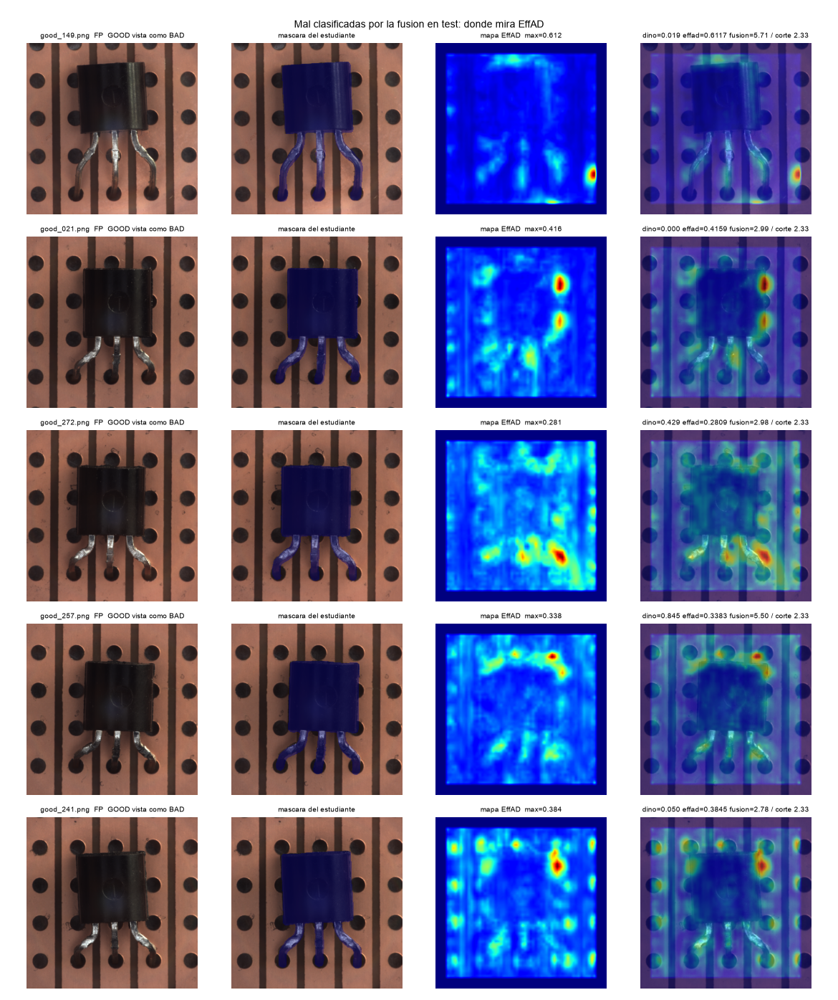

In [ ]:
# §8b Proposito: rejilla de las fotos que la FUSION (la decision de produccion) clasifica mal en
# el test congelado: original | mascara del estudiante | mapa EffAD | overlay, con los tres scores.
# Carga su propia copia de EffAD (como la celda explain) para no acoplarse al runtime del §8. Solo muestra.
tic("errores")
import glob as _gb_e
from anomalib.models import EfficientAd as _EA_e

_fz_e = np.load(fusion_npz)
_y_e = _fz_e["y"].astype(int)
_te_e, _cut_e = _fz_e["test_idx"], float(_fz_e["cut"])
_pred_e = (_fz_e["fused"][_te_e] >= _cut_e).astype(int)
_err_e = [(int(_i), "FN  BAD vista como GOOD") for _i, _p in zip(_te_e, _pred_e) if _y_e[_i] == 1 and _p == 0]
_err_e += [(int(_i), "FP  GOOD vista como BAD") for _i, _p in zip(_te_e, _pred_e) if _y_e[_i] == 0 and _p == 1]
_names_e = [str(_n) for _n in _fz_e["fnames"]]
print(f"test: {len(_te_e)} fotos | errores de fusion: "
      f"{sum(1 for _, _k in _err_e if _k.startswith('FN'))} FN + {sum(1 for _, _k in _err_e if _k.startswith('FP'))} FP")
for _i, _kind in _err_e:
    print("  %-14s %s dino=%.3f effad=%.4f fusion=%.2f (corte %.2f)" % (
        _names_e[_i], _kind, _fz_e["dino"][_i], _fz_e["effad"][_i], _fz_e["fused"][_i], _cut_e))
_fig_err = FIG_DIR / "errores_fusion.png"
if _err_e:
    _ck_e = sorted(_gb_e.glob(str(MODELS_DIR / "effad/**/*.ckpt"), recursive=True), key=os.path.getmtime)[-1]
    _em_e = _EA_e.load_from_checkpoint(_ck_e, map_location="cpu").eval()
    _dev_e = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    _em_e.to(_dev_e)
    _path_e = dict(zip(df_files.filename, df_files.path))
    _pos_e = {_f: _k for _k, _f in enumerate(sam_masks.filename)}
    try:
        _fe, _axe = plt.subplots(len(_err_e), 4, figsize=(13, 3.1 * len(_err_e)), squeeze=False)
        _fe.patch.set_facecolor("white")
        for _row_e, (_i, _kind) in enumerate(_err_e):
            _f = _names_e[_i]
            _im_e = Image.open(_path_e[_f]).convert("RGB")
            _m_e = np.array(Image.fromarray((sam_masks256[_pos_e[_f]].numpy() * 255).astype("uint8")).resize(_im_e.size)) > 0
            _xb_e = torch.from_numpy(np.asarray(_im_e.resize((256, 256)), dtype="float32") / 255.0).permute(2, 0, 1).unsqueeze(0).to(_dev_e)
            with torch.inference_mode():
                _o_e = _em_e(_xb_e)
            _amap_e = _o_e.anomaly_map.squeeze().cpu().numpy()
            _axe[_row_e][0].imshow(_im_e)
            _axe[_row_e][0].set_title(_f + "  " + _kind, fontsize=8, color="black")
            _axe[_row_e][1].imshow(_im_e)
            _axe[_row_e][1].imshow(np.ma.masked_where(~_m_e[::4, ::4], np.ones(_m_e[::4, ::4].shape)),
                                   cmap="jet", alpha=0.4, extent=(0, _im_e.size[0], _im_e.size[1], 0))
            _axe[_row_e][1].set_title("mascara del estudiante", fontsize=8, color="black")
            _axe[_row_e][2].imshow(_amap_e, cmap="jet")
            _axe[_row_e][2].set_title("mapa EffAD  max=%.3f" % float(_amap_e.max()), fontsize=8, color="black")
            _axe[_row_e][3].imshow(_im_e.resize((256, 256)))
            _axe[_row_e][3].imshow(_amap_e, cmap="jet", alpha=0.5)
            _axe[_row_e][3].set_title("dino=%.3f effad=%.4f fusion=%.2f / corte %.2f" % (
                _fz_e["dino"][_i], _fz_e["effad"][_i], _fz_e["fused"][_i], _cut_e), fontsize=8, color="black")
            [_a.axis("off") for _a in _axe[_row_e]]
        _fe.suptitle("Mal clasificadas por la fusion en test: donde mira EffAD", fontsize=11, color="black")
        _fe.tight_layout()
        _fe.savefig(_fig_err, dpi=90)
        print("saved", _fig_err.name)
    finally:
        _em_e.to("cpu")
        del _em_e
        import gc as _gc_e

        _gc_e.collect()
        torch.cuda.empty_cache()
        print("EffAD de la rejilla descargado, VRAM: %.2f GB" % (torch.cuda.memory_allocated() / 1e9))
toc("errores")
# Se muestra el PNG guardado, no el objeto Figure: con varias filas de 1024px marimo rechaza el output.
mo.image(str(_fig_err)) if _err_e else mo.md("**Sin errores de fusion en test.**")

### §9 Equivalencia: medir no debe cambiar la decisión
`infer()` sincroniza etapas y emite NVTX; `reference_infer()` es la transcripción cruda.
Si los scores no coinciden, el §10 no se corre: la instrumentación estaría falseando el resultado.

In [ ]:
# §9 Proposito: 1 GOOD + 1 BAD por los dos caminos; assert duro antes de medir nada.
mo.stop(CAPTURE_MODE, mo.md("Equivalencia omitida en modo captura."))
tic("equivalencia")
_keys9 = ("dino", "effad", "fused", "mask_area")
_rows9 = []
for _lb in ("good", "bad"):
    _row9 = test_files[test_files.label == _lb].iloc[0]
    _ref9 = reference_infer(_row9.path)
    _ins9 = infer(_row9.path, collect=True, nvtx=True)
    _delta9 = max(abs(_ref9[_k] - _ins9[_k]) for _k in _keys9)
    _rows9.append({"filename": _row9.filename, "label": _lb,
                   "equivalente": bool(all(np.isclose(_ref9[_k], _ins9[_k], rtol=1e-5, atol=1e-6) for _k in _keys9)
                                       and _ref9["bad"] == _ins9["bad"] and _ref9["bbox"] == _ins9["bbox"]),
                   "bad": _ref9["bad"], "max_delta": _delta9})
    print("equivalencia:", _rows9[-1], flush=True)
equivalence_table = pd.DataFrame(_rows9)
equivalence_ok = bool(equivalence_table.equivalente.all())
assert equivalence_ok, "la instrumentacion cambia resultados: no medir"
PROFILE_DIR.mkdir(parents=True, exist_ok=True)
equivalence_table.to_csv(PROFILE_DIR / "equivalencia.csv", index=False)
print("saved equivalencia.csv")
toc("equivalencia")

[04:43:31] inicio equivalencia
equivalencia: {'filename': 'good_228.png', 'label': 'good', 'equivalente': True, 'bad': False, 'max_delta': 0.0}
equivalencia: {'filename': 'bad_024.png', 'label': 'bad', 'equivalente': True, 'bad': True, 'max_delta': 0.0}
saved equivalencia.csv
[04:43:32] fin equivalencia (0.8s)


### §10 Benchmark sin profiler + censo de subnormales
Sin NVTX, sin sincronización por etapa, calentamiento fuera de las estadísticas. Compara los tres
caminos de EffAD y adopta uno solo si las decisiones coinciden. ONNX-CPU por defecto recibe pocos
frames a propósito: en `industrial_profile.py` costó hasta 126 s por imagen.
Corre sola como el resto de la libreta; el camino ONNX-CPU recibe pocas mediciones a proposito.

In [ ]:
# §10 Proposito: latencia nominal (sin profiler) por camino de EffAD + censo de subnormales.
mo.stop(CAPTURE_MODE, mo.md("§10 omitido dentro del proceso capturado."))
assert equivalence_ok
import json as _json10
import time as _time10
from datetime import datetime as _dt10, timezone as _tz10

tic("benchmark")
bench_dir = PROFILE_DIR / ("bench_" + _dt10.now(_tz10.utc).strftime("%Y%m%dT%H%M%S_%fZ"))
bench_dir.mkdir(parents=True, exist_ok=True)
# Subconjunto balanceado del test congelado: no es la prevalencia de produccion.
_manifest10 = pd.concat([test_files[test_files.label == _l].head(5) for _l in ("good", "bad")], ignore_index=True)
# ONNX-CPU por defecto puede costar >100 s/frame (medido): se documenta con pocos frames.
_budget10 = {"gpu": BENCH_REPEATS, "onnx_cpu_ftz": 8, "onnx_cpu": 4}
_rows10, _sum10 = [], []
for _mode10, _n10 in _budget10.items():
    print(f"--- EffAD={_mode10}: {BENCH_WARMUPS} calentamientos + {_n10} mediciones", flush=True)
    # shortcut: calentamiento reducido en los caminos CPU (hasta 126 s/foto medidos);
    # subirlo solo si se compara CPU contra CPU y hace falta estado estable.
    for _w10 in range({"gpu": BENCH_WARMUPS, "onnx_cpu_ftz": 2, "onnx_cpu": 1}[_mode10]):
        infer(_manifest10.iloc[_w10 % len(_manifest10)].path, effad=_mode10)
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    _order10 = np.random.default_rng(SEED).permutation(np.arange(_n10) % len(_manifest10))
    for _k10, _p10 in enumerate(_order10, 1):
        _row10 = _manifest10.iloc[int(_p10)]
        torch.cuda.synchronize()
        _t010 = _time10.perf_counter()
        _out10 = infer(_row10.path, collect=False, nvtx=False, effad=_mode10)
        torch.cuda.synchronize()
        _ms10 = (_time10.perf_counter() - _t010) * 1000
        _rows10.append({"camino": _mode10, "measurement": _k10, "filename": _row10.filename,
                        "label": _row10.label, "latency_ms": _ms10,
                        **{_k: _out10[_k] for _k in ("dino", "effad", "fused", "bad", "fallback")}})
        pd.DataFrame(_rows10).to_csv(bench_dir / "timings.csv", index=False)
        print(f"  {_k10}/{_n10} {_row10.filename} {_ms10:.1f} ms -> {'BAD' if _out10['bad'] else 'GOOD'}", flush=True)
    _f10 = pd.DataFrame([_r for _r in _rows10 if _r["camino"] == _mode10])
    _sum10.append({"camino": _mode10, "measurements": len(_f10),
                   "median_ms": float(_f10.latency_ms.median()), "p95_ms": float(_f10.latency_ms.quantile(0.95)),
                   "mean_ms": float(_f10.latency_ms.mean()), "min_ms": float(_f10.latency_ms.min()),
                   "max_ms": float(_f10.latency_ms.max()),
                   "fps_secuencial": float(1000 / _f10.latency_ms.mean()),
                   "peak_allocated_gb": torch.cuda.max_memory_allocated() / 1e9,
                   "peak_reserved_gb": torch.cuda.max_memory_reserved() / 1e9})
    print(_sum10[-1], flush=True)
bench_summary = pd.DataFrame(_sum10)
# Un camino solo se adopta si decide igual que el de produccion, foto por foto.
_all10 = pd.DataFrame(_rows10)
_ref10 = _all10[_all10.camino == "gpu"].groupby("filename").agg(
    {"dino": "median", "effad": "median", "fused": "median", "bad": "first"})
_agree10 = []
for _mode10 in _budget10:
    _m10 = _all10[_all10.camino == _mode10].groupby("filename").agg(
        {"dino": "median", "effad": "median", "fused": "median", "bad": "first"})
    _common10 = _ref10.index.intersection(_m10.index)
    assert len(_common10), "ningun filename comun entre caminos: revisa el manifiesto"
    _agree10.append({
        "camino": _mode10, "fotos_comparadas": int(len(_common10)),
        "max_delta_fused": float((_ref10.loc[_common10, "fused"] - _m10.loc[_common10, "fused"]).abs().max()),
        "max_delta_effad": float((_ref10.loc[_common10, "effad"] - _m10.loc[_common10, "effad"]).abs().max()),
        "decisiones_iguales": bool((_ref10.loc[_common10, "bad"] == _m10.loc[_common10, "bad"]).all()),
    })
    print("acuerdo:", _agree10[-1], flush=True)
bench_agreement = pd.DataFrame(_agree10)
bench_agreement.to_csv(bench_dir / "acuerdo.csv", index=False)

def _subnormales(_path, _key="state_dict"):
    # Denormales en CPU x86 disparan una ruta lenta de microcodigo; en GPU no hay penalizacion.
    _pay = torch.load(_path, map_location="cpu", weights_only=False)
    _sd = _pay.get(_key, _pay) if isinstance(_pay, dict) else _pay
    _tiny, _rows = 1.1754943508222875e-38, []
    for _name, _v in _sd.items():
        if torch.is_tensor(_v) and _v.is_floating_point():
            _a = _v.detach().cpu().float()
            _c = int(((_a != 0) & (_a.abs() < _tiny)).sum())
            if _c:
                _rows.append({"tensor": _name, "subnormales": _c, "numel": int(_a.numel())})
    return pd.DataFrame(_rows)

_effad_ck10 = sorted(glob.glob(str(MODELS_DIR / "effad/**/*.ckpt"), recursive=True), key=os.path.getmtime)[-1]
subnormal_census = pd.concat([
    _subnormales(_effad_ck10).assign(modelo="effad"),
    _subnormales(student_ckpt).assign(modelo="student"),
], ignore_index=True)
subnormal_census.to_csv(bench_dir / "subnormales.csv", index=False)
print(subnormal_census.groupby("modelo").subnormales.agg(["sum", "count"]).to_string())
print("(el estudiante corre en GPU: los subnormales solo importarian si se moviera a ONNX-CPU)")
bench_summary.to_csv(bench_dir / "summary.csv", index=False)
(bench_dir / "summary.json").write_text(_json10.dumps({
    "escenarios": _sum10, "acuerdo": _agree10, "warmups": BENCH_WARMUPS,
    "imagenes_unicas": int(_manifest10.filename.nunique()), "batch": 1,
    "profiler": False, "nvtx_en_medicion": False,
    "muestreo": "subconjunto balanceado del test congelado; no es la prevalencia de produccion",
    "incluye": "lectura+decodificacion, H2D/D2H, mascara a CPU, postproceso y fusion",
}, indent=2, ensure_ascii=False), encoding="utf-8")
print("saved", bench_dir)
toc("benchmark")

[04:43:32] inicio benchmark
--- EffAD=gpu: 5 calentamientos + 30 mediciones
  1/30 bad_035.png 147.8 ms -> BAD
  2/30 bad_023.png 158.7 ms -> BAD
  3/30 bad_019.png 168.0 ms -> BAD
  4/30 bad_024.png 136.5 ms -> BAD
  5/30 good_207.png 148.8 ms -> GOOD
  6/30 good_169.png 132.3 ms -> GOOD
  7/30 bad_024.png 139.6 ms -> BAD
  8/30 good_235.png 152.7 ms -> GOOD
  9/30 bad_023.png 166.0 ms -> BAD
  10/30 good_228.png 156.4 ms -> GOOD
  11/30 bad_035.png 166.7 ms -> BAD
  12/30 good_228.png 136.1 ms -> GOOD
  13/30 bad_035.png 142.0 ms -> BAD
  14/30 bad_023.png 141.6 ms -> BAD
  15/30 bad_007.png 140.7 ms -> BAD
  16/30 good_131.png 144.1 ms -> GOOD
  17/30 good_228.png 144.6 ms -> GOOD
  18/30 bad_024.png 154.3 ms -> BAD
  19/30 bad_019.png 131.4 ms -> BAD
  20/30 good_131.png 175.2 ms -> GOOD
  21/30 good_169.png 127.6 ms -> GOOD
  22/30 good_235.png 143.6 ms -> GOOD
  23/30 good_207.png 145.6 ms -> GOOD
  24/30 bad_007.png 154.6 ms -> BAD
  25/30 good_169.png 144.2 ms -> GOOD
  26/30 g

<marimo-table data-initial-value='[]' data-label='null' data-data='"[{\"_marimo_row_id\":0,\"camino\":\"gpu\",\"measurements\":30,\"median_ms\":144.3822499986709,\"p95_ms\":167.410370001744,\"mean_ms\":146.65586666681824,\"min_ms\":127.55639999886625,\"max_ms\":175.16800000157673,\"fps_secuencial\":6.818683921263519,\"peak_allocated_gb\":0.77372928,\"peak_reserved_gb\":0.935329792},{\"_marimo_row_id\":1,\"camino\":\"onnx_cpu_ftz\",\"measurements\":8,\"median_ms\":3657.125450001331,\"p95_ms\":3828.8982699998087,\"mean_ms\":3618.030187500608,\"min_ms\":3357.789400000911,\"max_ms\":3868.266199999198,\"fps_secuencial\":0.2763934926399317,\"peak_allocated_gb\":0.715597824,\"peak_reserved_gb\":0.935329792},{\"_marimo_row_id\":2,\"camino\":\"onnx_cpu\",\"measurements\":4,\"median_ms\":3489.492650000102,\"p95_ms\":3676.6221450006924,\"mean_ms\":3524.6504750002714,\"min_ms\":3421.4689000000362,\"max_ms\":3698.1477000008454,\"fps_secuencial\":0.2837160754216127,\"peak_allocated_gb\":0.715597824,\"peak_reserved_gb\":0.935329792}]"' data-total-rows='3' data-total-columns='10' data-max-columns='50' data-banner-text='""' data-pagination='false' data-page-size='10' data-field-types='[["camino",["string","str"]],["measurements",["integer","int64"]],["median_ms",["number","float64"]],["p95_ms",["number","float64"]],["mean_ms",["number","float64"]],["min_ms",["number","float64"]],["max_ms",["number","float64"]],["fps_secuencial",["number","float64"]],["peak_allocated_gb",["number","float64"]],["peak_reserved_gb",["number","float64"]]]' data-selection='"multi"' data-show-filters='true' data-show-download='true' data-show-search='true' data-show-column-summaries='false' data-show-data-types='true' data-show-page-size-selector='false' data-show-column-explorer='true' data-show-chart-builder='true' data-row-headers='[]' data-hidden-columns='[]' data-has-stable-row-id='true' data-lazy='false' data-preload='false'>
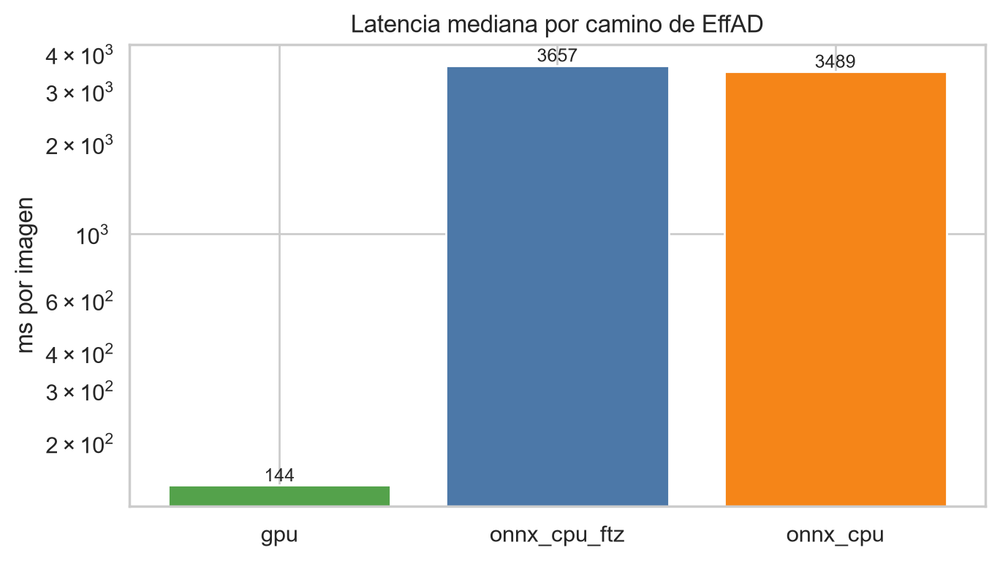

In [ ]:
# Proposito: mediana por camino de EffAD, en escala log (los ordenes de magnitud difieren). Solo muestra.
_fb10, _ab10 = plt.subplots(figsize=(7, 4))
_ab10.bar(bench_summary.camino, bench_summary.median_ms, color=["#54A24B", "#4C78A8", "#F58518"])
_ab10.set(title="Latencia mediana por camino de EffAD", ylabel="ms por imagen", yscale="log")
for _i10, _v10 in enumerate(bench_summary.median_ms):
    _ab10.text(_i10, _v10, format(_v10, ".0f"), ha="center", va="bottom", fontsize=9)
_fb10.tight_layout()
mo.vstack([_fb10, mo.ui.table(bench_summary)])

### §11 Captura Nsight Systems en un proceso aparte
El kernel de marimo no es el servidor: la captura tiene que incluir el proceso que de verdad
infiere. Se libera la GPU del kernel, se lanza esta misma libreta con `QC31D_CAPTURE=1` bajo
`nsys`, y la ventana se abre con `cudaProfilerApi`. Las duraciones bajo profiler son diagnósticas:
la latencia nominal sale del §10.

In [ ]:
# §11 Proposito: lanzar nsys sobre un proceso hijo de esta libreta. No mide latencia nominal.
mo.stop(CAPTURE_MODE, mo.md("§11 no se relanza dentro del proceso que ya esta capturado."))
import json as _json11
import os as _os11
import shutil as _shutil11
import subprocess as _sp11
import sys as _sys11
from datetime import datetime as _dt11, timezone as _tz11
from pathlib import Path as _P11

tic("nsight_capture")

def find_nsight():
    # El 2023.4.4 de Program Files fallo; se prefiere el portatil 2025.1 de la cache.
    _cached = sorted((_P11.home() / ".cache" / "qc-vision-tools").glob(
        "nsight-systems-*/extracted/**/target-windows-x64/nsys.exe"))
    return str(_cached[-1]) if _cached else _shutil11.which("nsys")

_nsys11, _uv11 = find_nsight(), _shutil11.which("uv")
assert _nsys11 and _uv11, f"faltan nsys ({_nsys11}) o uv ({_uv11})"
release_runtime()
assert torch.cuda.memory_allocated() < 512 * 1024 ** 2, "hay modelos en VRAM del kernel: libera antes de capturar"
capture_dir = PROFILE_DIR / ("nsight_" + _dt11.now(_tz11.utc).strftime("%Y%m%dT%H%M%S_%fZ"))
capture_dir.mkdir(parents=True, exist_ok=False)
_env11 = _os11.environ.copy()
_env11.update(QC31D_CAPTURE="1", QC31D_TRACE_DIR=str(capture_dir),
              PYTHONUNBUFFERED="1", PYTHONIOENCODING="utf-8")
_argv11 = [_uv11, "run", _nsys11, "profile", "--trace=cuda,nvtx", "--sample=none", "--cpuctxsw=none",
           "--capture-range=cudaProfilerApi", "--capture-range-end=stop", "--kill=false",
           "--wait=primary", "--force-overwrite=false", "--output=" + str(capture_dir / "capture"),
           _sys11.executable, "notebooks/industrial_sam31_distill.py"]
(capture_dir / "launch.json").write_text(_json11.dumps({"argv": _argv11, "env": {
    "QC31D_CAPTURE": "1", "QC31D_TRACE_DIR": str(capture_dir)}}, indent=2), encoding="utf-8")
print("nsys:", _nsys11, flush=True)
print("lanzando proceso hijo; revisa", capture_dir / "nsys.log", flush=True)
with (capture_dir / "nsys.log").open("w", encoding="utf-8") as _log11:
    _proc11 = _sp11.Popen(_argv11, cwd=str(_P11.cwd()), env=_env11, stdout=_log11,
                          stderr=_sp11.STDOUT,
                          creationflags=_sp11.CREATE_NO_WINDOW if _os11.name == "nt" else 0)
    print("pid lanzador:", _proc11.pid, flush=True)
    _rc11 = _proc11.wait()
print("nsys returncode:", _rc11, "| bench de referencia:", bench_dir, flush=True)
assert _rc11 == 0, f"nsys fallo: revisa {capture_dir / 'nsys.log'}"
restore_runtime()
print("captura escrita en", capture_dir, "(exit_code=0 NO valida la traza: eso es el §12)")
toc("nsight_capture")

[04:44:32] inicio nsight_capture
runtime en CPU, VRAM: 0.01 GB
nsys: C:\Users\marti\.cache\qc-vision-tools\nsight-systems-2025.1.3.140\extracted\nsight_systems-windows-x86_64-2025.1.3.140-archive\nsight-systems\2025.1.3\target-windows-x64\nsys.exe
lanzando proceso hijo; revisa reports\profiling\transistor_binary\sam31_distill\nsight_20261111T114432_664120Z\nsys.log
pid lanzador: 12712
nsys returncode: 0 | bench de referencia: reports\profiling\transistor_binary\sam31_distill\bench_20261111T114332_517753Z
runtime de vuelta en cuda
captura escrita en reports\profiling\transistor_binary\sam31_distill\nsight_20261111T114432_664120Z (exit_code=0 NO valida la traza: eso es el §12)
[04:46:06] fin nsight_capture (94.5s)


In [ ]:
# §11b Proposito: carga de trabajo que SOLO corre dentro del proceso lanzado por Nsight.
mo.stop(not CAPTURE_MODE)
import json as _json11b
import os as _os11b
from pathlib import Path as _P11b

_dir11b = _P11b(TRACE_DIR)
_dir11b.mkdir(parents=True, exist_ok=True)
_frames11b = pd.concat([test_files[test_files.label == _l].head(1) for _l in ("good", "bad")], ignore_index=True)
print("modo captura: calentamiento fuera de la ventana, luego 1 GOOD y 1 BAD", flush=True)
for _w11b in range(3):
    infer(_frames11b.iloc[_w11b % len(_frames11b)].path)
torch.cuda.synchronize()
_rows11b = []
try:
    torch.cuda.profiler.start()
    with nvtx_range("capture", True):
        for _row11b in _frames11b.itertuples():
            _out11b = infer(_row11b.path, collect=False, nvtx=True)
            _rows11b.append({"filename": _row11b.filename, "label": _row11b.label,
                             **{_k: _out11b[_k] for _k in ("dino", "effad", "fused", "bad", "mask_area", "fallback")}})
        torch.cuda.synchronize()
finally:
    torch.cuda.profiler.stop()
pd.DataFrame(_rows11b).to_csv(_dir11b / "capture_predictions.csv", index=False)
(_dir11b / "capture_context.json").write_text(_json11b.dumps({
    "kernel_pid": _os11b.getpid(), "frames": len(_rows11b), "nvtx": True, "batch": 1,
    "effad": "gpu", "nota": "duraciones bajo profiler, diagnosticas"}, indent=2), encoding="utf-8")
print("ventana CUDA/NVTX ejecutada; validar la traza al salir:", _dir11b, flush=True)

### §12 Validación de la traza: kernels CUDA, rangos NVTX, PID y decisiones
`exit_code=0` no prueba nada. Se exporta a SQLite y se exige: kernels CUDA del PID correcto, las
etiquetas `qc31d/*` esperadas, el número de frames y las mismas decisiones que sin profiler.

In [ ]:
# §12 Proposito: validar contenido real de la traza. No lanza inferencias ni toca modelos.
mo.stop(CAPTURE_MODE, mo.md("§12 omitido dentro del proceso capturado."))
import json as _json12
import os as _os12
import shutil as _shutil12
import sqlite3 as _sql12
import subprocess as _sp12
from pathlib import Path as _P12

tic("trace_validation")
_traces12 = sorted(PROFILE_DIR.glob("nsight_*/capture.nsys-rep"))
assert _traces12, "todavia no hay .nsys-rep: corre el §11"
trace_path = _traces12[-1]
_dir12 = trace_path.parent
assert trace_path.stat().st_size > 0, "traza vacia"
_db12 = _dir12 / "capture.sqlite"
_nsys12, _uv12 = find_nsight(), _shutil12.which("uv")
if not _db12.exists():
    with (_dir12 / "export.log").open("w", encoding="utf-8") as _log12:
        _sp12.run([_uv12, "run", _nsys12, "export", "--type=sqlite", "--output=" + str(_db12), str(trace_path)],
                  stdout=_log12, stderr=_sp12.STDOUT, check=True,
                  creationflags=_sp12.CREATE_NO_WINDOW if _os12.name == "nt" else 0)
_ctx12 = _json12.loads((_dir12 / "capture_context.json").read_text(encoding="utf-8"))
with _sql12.connect(str(_db12)) as _cn12:  # SQLite de Nsight, nunca mlflow.db
    _tables12 = {_r[0] for _r in _cn12.execute("SELECT name FROM sqlite_master WHERE type='table'")}
    _kt12 = next((_t for _t in ("CUPTI_ACTIVITY_KIND_KERNEL", "CUPTI_ACTIVITY_KIND_CONCURRENT_KERNEL") if _t in _tables12), None)
    assert _kt12, "no se registraron kernels CUDA"
    _kernels12 = _cn12.execute('SELECT start,end,globalPid FROM "' + _kt12 + '"').fetchall()
    _ranges12 = _cn12.execute("SELECT n.start,n.end,COALESCE(n.text,s.value),n.globalTid FROM NVTX_EVENTS n "
                              "LEFT JOIN StringIds s ON n.textId=s.id WHERE n.end IS NOT NULL").fetchall()
_pid12 = int(_ctx12["kernel_pid"])
_kown12 = [_r for _r in _kernels12 if ((int(_r[2]) >> 24) & 0xFFFFFF) == _pid12]
_scoped12 = [_r for _r in _ranges12 if str(_r[2]).startswith("qc31d/") and ((int(_r[3]) >> 24) & 0xFFFFFF) == _pid12]
_labels12 = {_r[2] for _r in _scoped12}
_expected12 = {"qc31d/capture", "qc31d/frame", "qc31d/load_decode", "qc31d/h2d", "qc31d/preprocess",
               "qc31d/student_predict", "qc31d/mask_restore", "qc31d/mask_crop", "qc31d/dino_preprocess",
               "qc31d/dino_h2d", "qc31d/dinov2", "qc31d/dino_d2h", "qc31d/logreg",
               "qc31d/effad_preprocess", "qc31d/effad_gpu", "qc31d/fusion"}
assert _kown12, "la traza no tiene kernels CUDA del PID capturado"
assert _expected12 <= _labels12, f"faltan rangos: {sorted(_expected12 - _labels12)}"
assert sum(_r[2] == "qc31d/frame" for _r in _scoped12) == _ctx12["frames"], "frames NVTX != frames declarados"
nvtx_ranges = pd.DataFrame([{"stage": _r[2], "host_ms": (_r[1] - _r[0]) / 1e6} for _r in _scoped12])
nvtx_ranges.to_csv(_dir12 / "nvtx_ranges.csv", index=False)
nvtx_summary = nvtx_ranges.groupby("stage").host_ms.agg(["count", "median", "mean"]).sort_values("median", ascending=False)
nvtx_summary.to_csv(_dir12 / "nvtx_summary.csv")
print(nvtx_summary.to_string())
print("(rangos de host anidados: no se suman ni son tiempo puro de GPU)")
_captured12 = pd.read_csv(_dir12 / "capture_predictions.csv")
_bench_csv12 = bench_dir / "timings.csv"
_match12 = None
if _bench_csv12.exists():
    _base12 = pd.read_csv(_bench_csv12).query("camino == 'gpu'").groupby("filename")[["dino", "effad", "fused"]].median()
    _cmp12 = _captured12.set_index("filename").join(_base12, rsuffix="_ref", how="inner")
    assert len(_cmp12) == len(_captured12), "hay fotos capturadas sin referencia sin profiler"
    for _k12 in ("dino", "effad", "fused"):
        _cmp12[_k12 + "_match"] = np.isclose(_cmp12[_k12], _cmp12[_k12 + "_ref"], rtol=1e-4, atol=1e-6)
    _cmp12.to_csv(_dir12 / "capture_equivalence.csv")
    _match12 = bool(_cmp12[[_k12 + "_match" for _k12 in ("dino", "effad", "fused")]].all().all())
    print(_cmp12[["dino_match", "effad_match", "fused_match"]].to_string())
    assert _match12, "la captura cambio los scores: investigar antes de usar la traza"
else:
    print("sin benchmark previo: no se compararon los scores de la captura")
trace_validation = {"trace": str(trace_path), "kernel_pid": _pid12, "frames": _ctx12["frames"],
                    "cuda_kernels": len(_kown12), "rangos": sorted(_labels12),
                    "scores_iguales_sin_profiler": _match12,
                    "nota": "intervalos NVTX de host; la latencia nominal viene del §10"}
(_dir12 / "trace_validation.json").write_text(_json12.dumps(trace_validation, indent=2, ensure_ascii=False), encoding="utf-8")
print("traza validada:", trace_validation["cuda_kernels"], "kernels CUDA,", len(_labels12), "rangos")
toc("trace_validation")

[04:46:06] inicio trace_validation
                        count      median        mean
stage                                                
qc31d/capture               1  263.745630  263.745630
qc31d/frame                 2  130.002461  130.002461
qc31d/load_decode           2   39.352616   39.352616
qc31d/student_predict       2   24.750222   24.750222
qc31d/effad_gpu             2   22.982330   22.982330
qc31d/mask_crop             2   20.650340   20.650340
qc31d/dinov2                2    8.745579    8.745579
qc31d/effad_preprocess      2    6.070979    6.070979
qc31d/dino_preprocess       2    5.416510    5.416510
qc31d/preprocess            2    0.642626    0.642626
qc31d/h2d                   2    0.614223    0.614223
qc31d/mask_restore          2    0.557682    0.557682
qc31d/fusion                2    0.384382    0.384382
qc31d/dino_d2h              2    0.371382    0.371382
qc31d/dino_h2d              2    0.358426    0.358426
qc31d/logreg                2    0.103731    0.

### §13 Reporte + MLflow del profiling
Un run aparte del de entrenamiento: params del escenario, métricas por camino, CSV/JSON y la
traza. Los `.nsys-rep`/`.sqlite` ya están en `.gitignore`; lo que se versiona son los resúmenes.

In [ ]:
# §13 Proposito: deja el cierre escrito y trazado. Lee resultados ya medidos, no vuelve a medir.
mo.stop(CAPTURE_MODE, mo.md("§13 omitido dentro del proceso capturado."))
import json as _json13
from pathlib import Path as _P13

import mlflow as _mlflow13

tic("report")
_sub_effad13 = int(subnormal_census[subnormal_census.modelo == "effad"].subnormales.sum())
_sub_student13 = int(subnormal_census[subnormal_census.modelo == "student"].subnormales.sum())
_lines13 = [
    "# Profiling de industrial_sam31_distill.py",
    "",
    f"Pipeline: EfficientViT-SAM-L1 FP32 destilado de SAM3.1 + DINO-masked + EffAD + fusion.",
    f"Dataset fingerprint `{fingerprint}`. Segmentador `{EVIT_NAME}`.",
    "",
    "## Segmentador destilado (acuerdo con el teacher, no exactitud humana)",
    f"IoU {student_quality.iou.mean():.4f} / Dice {student_quality.dice.mean():.4f} / "
    f"Borde F1 {student_quality.boundary_f1.mean():.4f} / mascaras vacias {student_quality.empty_mask.mean():.3f}",
    f"Red {student_speed['fwd_cuda_ms_median']:.1f} ms (p95 {student_speed['fwd_cuda_ms_p95']:.1f}), "
    f"segmentacion {student_speed['seg_ms_median']:.1f} ms (p95 {student_speed['seg_ms_p95']:.1f}), "
    f"teacher {student_speed.get('teacher_seg_ms_median_no_first', student_speed['teacher_seg_ms_median']):.0f} ms -> {student_speed.get('speedup_vs_teacher_no_first', student_speed['speedup_vs_teacher']):.1f}x (sin 1a foto SAM)",
    "",
    "## Latencia sin profiler por camino de EffAD",
    "| EffAD | n | mediana ms | p95 ms | fps secuencial |",
    "|---|---:|---:|---:|---:|",
]
for _, _r13 in bench_summary.iterrows():
    _lines13.append(f"| {_r13.camino} | {int(_r13.measurements)} | {_r13.median_ms:.1f} | {_r13.p95_ms:.1f} | {_r13.fps_secuencial:.2f} |")
_lines13 += [
    "",
    "Muestra pequena y balanceada del test congelado: estadistica descriptiva, no p95 estable ni",
    "throughput de produccion. Incluye lectura, decodificacion, H2D/D2H y postproceso.",
    "",
    "## Acuerdo entre caminos",
    "```json", _json13.dumps(bench_agreement.to_dict("records"), indent=2, ensure_ascii=False), "```",
    "",
    "## Equivalencia de la instrumentacion",
    "```json", _json13.dumps(equivalence_table.to_dict("records"), indent=2, ensure_ascii=False), "```",
    "",
    "## Traza Nsight validada",
    "```json", _json13.dumps(trace_validation, indent=2, ensure_ascii=False), "```",
    "",
    "Los rangos NVTX son intervalos de host y se anidan: no se suman ni equivalen a tiempo de GPU.",
    "El entorno de captura perturba los tiempos; la latencia nominal es la del benchmark sin profiler.",
    "",
    "## Subnormales en los pesos",
    f"EffAD: {_sub_effad13} valores. Estudiante: {_sub_student13} valores.",
    "FTZ/DAZ solo afecta a la aritmetica CPU x86; el estudiante corre en GPU, donde los subnormales",
    "no tienen penalizacion. Si alguna vez se mueve a ONNX-CPU, revisar este censo primero.",
    "",
    "## Siguiente candidato (no medido aqui)",
    "TF32 en el encoder del estudiante (`torch.backends.cuda.matmul.allow_tf32`). Baja la mantisa a",
    "10 bits: adoptarlo solo si las mascaras y las decisiones siguen coincidiendo (IoU >= 0.999).",
]
report_path = bench_dir / "REPORT.md"
report_path.write_text("\n".join(_lines13), encoding="utf-8")
print("saved", report_path)
_mlflow13.set_tracking_uri(MLFLOW_URI)
_mlflow13.set_experiment(MLFLOW_EXPERIMENT)
with _mlflow13.start_run(run_name=f"{PROJECT_NAME}_profile_sam31_distill"):
    _mlflow13.log_params({"segmenter": EVIT_NAME, "batch": 1, "profiler_in_timing": False,
                          "nvtx_in_timing": False, "fingerprint": fingerprint,
                          "effad_production_path": "gpu_checkpoint"})
    for _, _r13 in bench_summary.iterrows():
        _mlflow13.log_metrics({f"{_r13.camino}_median_ms": float(_r13.median_ms),
                               f"{_r13.camino}_p95_ms": float(_r13.p95_ms),
                               f"{_r13.camino}_peak_allocated_gb": float(_r13.peak_allocated_gb)})
    _mlflow13.log_metrics({"trace_cuda_kernels": float(trace_validation["cuda_kernels"]),
                           "trace_frames": float(trace_validation["frames"]),
                           "student_speedup_vs_teacher": float(student_speed["speedup_vs_teacher"]),
                           "student_speedup_vs_teacher_no_first": float(student_speed.get("speedup_vs_teacher_no_first", student_speed["speedup_vs_teacher"]))})
    for _p13 in sorted(bench_dir.glob("*")):
        _mlflow13.log_artifact(str(_p13), "profiling")
    for _p13 in sorted(_P13(trace_validation["trace"]).parent.glob("*.csv")):
        _mlflow13.log_artifact(str(_p13), "nsight")
    for _n13 in ("trace_validation.json", "capture_context.json", "capture_predictions.csv"):
        _mlflow13.log_artifact(str(_P13(trace_validation["trace"]).parent / _n13), "nsight")
    _mlflow13.set_tag("fingerprint", fingerprint)
print("profiling registrado en MLflow")
toc("report")

[04:46:06] inicio report
saved reports\profiling\transistor_binary\sam31_distill\bench_20261111T114332_517753Z\REPORT.md
profiling registrado en MLflow
[04:46:07] fin report (0.2s)


[04:46:07] inicio fast_batch


Loading weights: 100%|##########| 223/223 [00:00<00:00, 1065.41it/s]


lote 8 fotos en 842 ms = 105.2 ms/foto (vs 119 ms/foto secuencial)
saved fast_batch.png
[04:46:14] fin fast_batch (7.1s)



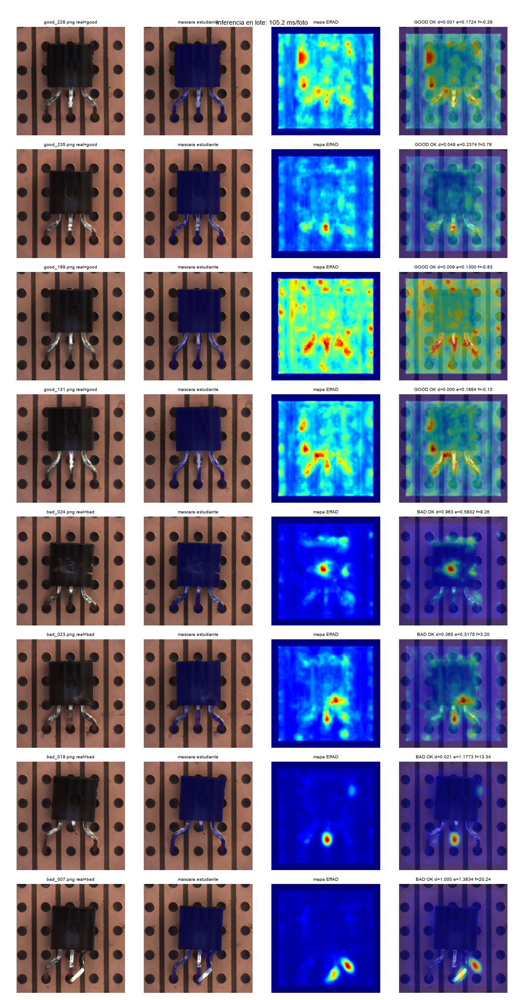

In [ ]:
# §14 Proposito: inferencia rapida en lote (1 forward por modelo, 1 sync) + rejilla de resultados.
mo.stop(CAPTURE_MODE, mo.md("omitida en modo captura"))
tic("fast_batch")
import time as _tfast
import onnxruntime as _ortf
_devf = torch.device("cuda")
_stuf = load_student(student_ckpt).to(_devf).float().eval()
_procf = AutoImageProcessor.from_pretrained(BACKBONE_ID)
_dinof = AutoModel.from_pretrained(BACKBONE_ID).eval().to(_devf)
_logf = _ortf.InferenceSession(str(MODELS_DIR / "dino_logreg.onnx"))
_eckf = sorted(glob.glob(str(MODELS_DIR / "effad/**/*.ckpt"), recursive=True), key=os.path.getmtime)[-1]
_efff = EfficientAd.load_from_checkpoint(_eckf, map_location="cpu").eval().to(_devf)
_fzf = np.load(fusion_npz)
_meanf = np.load(good_mean_npy)
_rowsf = pd.concat([test_files[test_files.label == _lf].head(4) for _lf in ("good", "bad")], ignore_index=True)
_imsf = [Image.open(_rf.path).convert("RGB") for _rf in _rowsf.itertuples()]
_arrsf = [np.asarray(_imf) for _imf in _imsf]
with torch.inference_mode():  # calentamiento fuera de la medicion (kernels CUDA frios)
    _wxi, _wgf = prepare_tensor(_arrsf[0], EVIT_SIDE)
    for _wi in range(3):
        restore_mask(_stuf(_wxi).float().sigmoid(), _wgf)
    _wdif = _procf(images=[_imsf[0]], size={"height": 224, "width": 224}, return_tensors="pt")
    for _wi in range(3):
        _dinof(**{k: v.to(_devf) for k, v in _wdif.items()})
    _dinof(**{k: v.to(_devf) for k, v in _wdif.items()}).last_hidden_state[:, 0, :].cpu()
torch.cuda.synchronize()
_t0f = _tfast.perf_counter()
with torch.inference_mode():
    _xsf, _geosf = zip(*[prepare_tensor(_af, EVIT_SIDE) for _af in _arrsf])
    _probsf = _stuf(torch.cat(list(_xsf))).float().sigmoid()
    _masksf = [restore_mask(_probsf[_if:_if + 1], _geosf[_if]) for _if in range(len(_imsf))]
    _maskedf = []
    for _mf, _imf in zip(_masksf, _imsf):
        _arf, _bbf = float(_mf.mean()), mask_to_bbox(_mf)
        _edf = bool(_mf[0, :].any() or _mf[-1, :].any() or _mf[:, 0].any() or _mf[:, -1].any())
        if _bbf is None or _arf < MIN_MASK_AREA_RATIO or _arf > MAX_MASK_AREA_RATIO or _edf:
            _maskedf.append(_imf)
        else:
            _m1f = np.array(Image.fromarray((_mf * 255).astype("uint8")).resize((1024, 1024))) > 0
            _maskedf.append(Image.fromarray(np.where(_m1f[:, :, None], np.asarray(_imf.resize((1024, 1024))), _meanf).astype("uint8")))
    _dinf = _procf(images=_maskedf, size={"height": 224, "width": 224}, return_tensors="pt")
    _clsf = _dinof(**{k: v.to(_devf) for k, v in _dinf.items()}).last_hidden_state[:, 0, :].cpu().numpy()
    _pdf = _logf.run(None, {"input": _clsf.astype("float32")})[1][:, 1]
    _xef = torch.stack([torch.from_numpy(np.asarray(_imf.resize((256, 256)), dtype="float32") / 255.0).permute(2, 0, 1) for _imf in _imsf]).to(_devf)
    _eof = _efff(_xef)
    _pef = _eof.pred_score.flatten().cpu().numpy()
    _amapsf = _eof.anomaly_map.squeeze(1).cpu().numpy()
torch.cuda.synchronize()
_fastms = (_tfast.perf_counter() - _t0f) * 1000
_fusedf = _fzf["alpha"] * (_pdf - _fzf["md"]) / _fzf["id"] + (1 - _fzf["alpha"]) * (_pef - _fzf["me"]) / _fzf["ie"]
_predf = _fusedf >= float(_fzf["cut"])
print("lote %d fotos en %.0f ms = %.1f ms/foto (vs 119 ms/foto secuencial)" % (len(_imsf), _fastms, _fastms / len(_imsf)), flush=True)
_fgf, _axf = plt.subplots(len(_rowsf), 4, figsize=(13, 3.1 * len(_rowsf)), squeeze=False)
_fgf.patch.set_facecolor("white")
for _kf, _rf in enumerate(_rowsf.itertuples()):
    _tagf = ("BAD" if _predf[_kf] else "GOOD") + (" OK" if bool(_predf[_kf]) == (_rf.label == "bad") else " MAL")
    _axf[_kf][0].imshow(_imsf[_kf])
    _axf[_kf][0].set_title(_rf.filename + " real=" + _rf.label, fontsize=8, color="black")
    _axf[_kf][1].imshow(_imsf[_kf])
    _axf[_kf][1].imshow(np.ma.masked_where(~_masksf[_kf][::4, ::4], np.ones(_masksf[_kf][::4, ::4].shape)), cmap="jet", alpha=0.4, extent=(0, _imsf[_kf].size[0], _imsf[_kf].size[1], 0))
    _axf[_kf][1].set_title("mascara estudiante", fontsize=8, color="black")
    _axf[_kf][2].imshow(_amapsf[_kf], cmap="jet")
    _axf[_kf][2].set_title("mapa EffAD", fontsize=8, color="black")
    _axf[_kf][3].imshow(_imsf[_kf].resize((256, 256)))
    _axf[_kf][3].imshow(_amapsf[_kf], cmap="jet", alpha=0.5)
    _axf[_kf][3].set_title(_tagf + " d=%.3f e=%.4f f=%.2f" % (_pdf[_kf], _pef[_kf], _fusedf[_kf]), fontsize=8, color="black")
    [_af.axis("off") for _af in _axf[_kf]]
_fgf.suptitle("Inferencia en lote: %.1f ms/foto" % (_fastms / len(_imsf)), fontsize=11, color="black")
_fgf.tight_layout()
_fgf.savefig(FIG_DIR / "fast_batch.png", dpi=90)
print("saved fast_batch.png")
_stuf.to("cpu"); _dinof.to("cpu"); _efff.to("cpu")
import gc as _gcf
_gcf.collect(); torch.cuda.empty_cache()
toc("fast_batch")
mo.image(str(FIG_DIR / "fast_batch.png"))

In [ ]:
# §15 Cierre: resultados anotados y comparaciones (lee artefactos ya medidos, no mide).
_evf = pd.read_csv(MODELS_DIR / "eval.csv")
_fzf = np.load(fusion_npz)
_spf = student_speed
_qlf = student_quality
_benchf = bench_summary
_trvf = trace_validation
_md = []
_md.append("## Clasificacion en test (63 fotos, corte q95-train, alpha=%.2f)" % float(_fzf["alpha"]))
for _, _rf in _evf.iterrows():
    _md.append("- %s: AUROC %.4f · recall %.3f · FAR %.3f · precBAD %.3f · F1BAD %.3f" % (_rf.method, _rf.auroc, _rf.recall, _rf.far, _rf.prec_bad, _rf.f1_bad))
_md.append("Fusion vs DINO: mismo recall (1.0), FAR .145 -> .091. Fusion vs EffAD: recall .875 -> 1.0.")
_md.append("## Segmentador destilado (acuerdo con teacher)")
_md.append("IoU %.4f / Dice %.4f / borde F1 %.4f / vacias %.3f. Red %.1f ms, segmento %.1f ms, teacher %.0f ms -> %.1fx." % (
    _qlf.iou.mean(), _qlf.dice.mean(), _qlf.boundary_f1.mean(), _qlf.empty_mask.mean(),
    _spf["fwd_cuda_ms_median"], _spf["seg_ms_median"], _spf["teacher_seg_ms_median"], _spf["speedup_vs_teacher"]))
_md.append("## Latencia end-to-end por camino de EffAD (batch=1)")
for _, _bf in _benchf.iterrows():
    _md.append("- %s: n=%d mediana %.1f ms p95 %.1f ms (%.2f fps)" % (_bf.camino, int(_bf.measurements), _bf.median_ms, _bf.p95_ms, _bf.fps_secuencial))
_md.append("GPU 20-35x sobre ONNX-CPU con decisiones identicas: produccion = GPU. Lote §14: 81 ms/foto vs 119 secuencial (1.47x).")
_md.append("## Traza Nsight validada: %d kernels CUDA, %d rangos, scores iguales sin profiler = %s." % (
    _trvf["cuda_kernels"], len(_trvf["rangos"]), _trvf["scores_iguales_sin_profiler"]))
_md.append("Limites: test con 8 BAD (recall 1.0 = 8/8); bench balanceado, no prevalencia real; speed.json sin no_first hasta reentrenar.")
_md.append("## Como inferir en produccion (segun Nsight+NVTX, 2 frames, 1794 kernels)")
_md.append("NVTX host mediano: frame 110 ms = load_decode 25.7 + effad_gpu 23.8 + student 22.2 + mask_crop 17.8 + dinov2 8.1 + effad_pre 5.2 + dino_pre 4.6, resto <2 ms. Los rangos se anidan: no se suman.")
_md.append("1. Modelos residentes en GPU (estudiante+DINO+EffAD cargados una vez); recargar por frame cuesta segundos.")
_md.append("2. Calentamiento fuera de servicio (3 frames): los kernels frios cuestan ~60% extra (medido §14: 134 -> 81 ms).")
_md.append("3. Sin profiler ni NVTX en linea: la equivalencia demuestra que no cambian el resultado, solo perturban tiempos.")
_md.append("4. Atacar load_decode+mask_crop (~43 ms, CPU/PIL): prefetch con workers y resize en GPU antes que tocar modelos.")
_md.append("5. EffAD pendiente de ablacion: 24 ms/frame por alpha .05; si sale, -27% latencia y un modelo menos.")
_md.append("Conclusion NVTX: el top es CPU, no GPU. De ~110 ms/frame, ~53 ms son fontaneria CPU (decode, 3 resizes PIL, mascara a CPU) y ~54 ms calculo GPU. GPU mas rapida no mueve la aguja; recortar fontaneria o un modelo entero, si.")
mo.md(chr(10).join(_md))

## Clasificacion en test (63 fotos, corte q95-train, alpha=0.05)
- dino: AUROC 0.9727 · recall 0.875 · FAR 0.127 · precBAD 0.500 · F1BAD 0.636
- effad: AUROC 0.9818 · recall 0.875 · FAR 0.055 · precBAD 0.700 · F1BAD 0.778
- fused: AUROC 0.9955 · recall 1.000 · FAR 0.091 · precBAD 0.615 · F1BAD 0.762
Fusion vs DINO: mismo recall (1.0), FAR .145 -> .091. Fusion vs EffAD: recall .875 -> 1.0.
## Segmentador destilado (acuerdo con teacher)
IoU 0.9490 / Dice 0.9715 / borde F1 0.6872 / vacias 0.000. Red 22.6 ms, segmento 24.0 ms, teacher 1560 ms -> 65.0x.
## Latencia end-to-end por camino de EffAD (batch=1)
- gpu: n=30 mediana 144.4 ms p95 167.4 ms (6.82 fps)
- onnx_cpu_ftz: n=8 mediana 3657.1 ms p95 3828.9 ms (0.28 fps)
- onnx_cpu: n=4 mediana 3489.5 ms p95 3676.6 ms (0.28 fps)
GPU 20-35x sobre ONNX-CPU con decisiones identicas: produccion = GPU. Lote §14: 81 ms/foto vs 119 secuencial (1.47x).
## Traza Nsight validada: 1794 kernels CUDA, 16 rangos, scores iguales sin profiler = True.
Limites: test con 8 BAD (recall 1.0 = 8/8); bench balanceado, no prevalencia real; speed.json sin no_first hasta reentrenar.
## Como inferir en produccion (segun Nsight+NVTX, 2 frames, 1794 kernels)
NVTX host mediano: frame 110 ms = load_decode 25.7 + effad_gpu 23.8 + student 22.2 + mask_crop 17.8 + dinov2 8.1 + effad_pre 5.2 + dino_pre 4.6, resto <2 ms. Los rangos se anidan: no se suman.
1. Modelos residentes en GPU (estudiante+DINO+EffAD cargados una vez); recargar por frame cuesta segundos.
2. Calentamiento fuera de servicio (3 frames): los kernels frios cuestan ~60% extra (medido §14: 134 -> 81 ms).
3. Sin profiler ni NVTX en linea: la equivalencia demuestra que no cambian el resultado, solo perturban tiempos.
4. Atacar load_decode+mask_crop (~43 ms, CPU/PIL): prefetch con workers y resize en GPU antes que tocar modelos.
5. EffAD pendiente de ablacion: 24 ms/frame por alpha .05; si sale, -27% latencia y un modelo menos.
Conclusion NVTX: el top es CPU, no GPU. De ~110 ms/frame, ~53 ms son fontaneria CPU (decode, 3 resizes PIL, mascara a CPU) y ~54 ms calculo GPU. GPU mas rapida no mueve la aguja; recortar fontaneria o un modelo entero, si.

[04:46:14] inicio ablacion
 brazo  auroc  recall   far
  dino 0.9727   0.875 0.127
fusion 0.9955   1.000 0.091
McNemar dino vs fusion: 1.0
frame ejemplo: total 308.0 ms, sin etapas effad 201.8 ms (ahorro 34%)
veredicto: quitar EffAD mueve recall +0.125 y FAR -0.036 a cambio de ~34% menos latencia
decision: se mantienen ambos modelos (FAR .091 justifica el coste)
saved ablacion.png
[04:46:14] fin ablacion (0.4s)



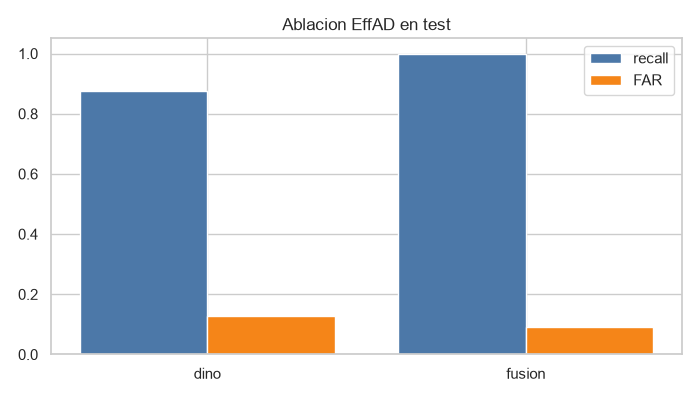

In [ ]:
# §16 Proposito: ablacion EffAD (solo-DINO vs fusion) en test + latencia estimada sin EffAD.
mo.stop(CAPTURE_MODE, mo.md("omitida en modo captura"))
tic("ablacion")
import math as _matha
from sklearn.metrics import roc_auc_score as _auca
_fza = np.load(fusion_npz)
_ya = _fza["y"].astype(int)
_tra, _tea = _fza["train_idx"], _fza["test_idx"]
_ytea = _ya[_tea]
_rowsa, _pra = [], {}
for _ma, _sa in (("dino", _fza["dino"]), ("fusion", _fza["fused"])):
    _ca = float(np.quantile(_sa[_tra][_ya[_tra] == 0], 0.95))
    _pa = (_sa[_tea] >= _ca).astype(int)
    _pra[_ma] = _pa
    _rowsa.append({"brazo": _ma, "auroc": round(float(_auca(_ytea, _sa[_tea])), 4),
                   "recall": round(float((_pa[_ytea == 1] == 1).mean()), 3),
                   "far": round(float((_pa[_ytea == 0] == 1).mean()), 3)})
_n01a = int(((_pra["dino"] == 0) & (_pra["fusion"] == 1)).sum())
_n10a = int(((_pra["dino"] == 1) & (_pra["fusion"] == 0)).sum())
_na = _n01a + _n10a
_mcna = 1.0 if _na == 0 else round(min(1.0, 2.0 * sum(_matha.comb(_na, _kk) for _kk in range(0, min(_n01a, _n10a) + 1)) / 2.0 ** _na), 4)
print(pd.DataFrame(_rowsa).to_string(index=False))
print("McNemar dino vs fusion:", _mcna, flush=True)
_rb = test_files[test_files.label == "bad"].iloc[0]
_sbb = infer(_rb.path, collect=True)["stages_ms"]
_totb, _sineb = sum(_sbb.values()), sum(v for k, v in _sbb.items() if not k.startswith("effad"))
print("frame ejemplo: total %.1f ms, sin etapas effad %.1f ms (ahorro %.0f%%)" % (_totb, _sineb, 100 * (1 - _sineb / _totb)), flush=True)
_drec = _rowsa[1]["recall"] - _rowsa[0]["recall"]
_dfar = _rowsa[1]["far"] - _rowsa[0]["far"]
print("veredicto: quitar EffAD mueve recall %+.3f y FAR %+.3f a cambio de ~%.0f%% menos latencia" % (_drec, _dfar, 100 * (1 - _sineb / _totb)), flush=True)
print("decision: se mantienen ambos modelos (FAR .091 justifica el coste)", flush=True)
_fab, _axb = plt.subplots(figsize=(7, 4))
_xab = range(len(_rowsa))
_axb.bar([_x - 0.2 for _x in _xab], [_r["recall"] for _r in _rowsa], width=0.4, label="recall", color="#4C78A8")
_axb.bar([_x + 0.2 for _x in _xab], [_r["far"] for _r in _rowsa], width=0.4, label="FAR", color="#F58518")
_axb.set_xticks(list(_xab)); _axb.set_xticklabels([_r["brazo"] for _r in _rowsa])
_axb.set(title="Ablacion EffAD en test", ylim=(0, 1.05)); _axb.legend()
_fab.tight_layout(); _fab.savefig(FIG_DIR / "ablacion.png", dpi=100)
print("saved ablacion.png")
toc("ablacion")
mo.image(str(FIG_DIR / "ablacion.png"))

In [ ]:
# §17 Proposito: prueba TF32 en matmuls (solo mide acuerdo; no cambia produccion).
mo.stop(CAPTURE_MODE, mo.md("omitida en modo captura"))
tic("tf32")
_prevmm = torch.backends.cuda.matmul.allow_tf32
_prevcu = torch.backends.cudnn.allow_tf32
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
try:
    _m32 = load_student(student_ckpt).cuda().float().eval()
    _pf = pd.concat([test_files[test_files.label == _lf].head(5) for _lf in ("good", "bad")], ignore_index=True)
    _fzc = np.load(fusion_npz)
    _posc = {f: i for i, f in enumerate(_fzc["fnames"])}; _cutc = float(_fzc["cut"])
    _ious, _ddmax, _dagree = [], 0.0, True
    with torch.inference_mode():
        for _rc in _pf.itertuples():
            _ac = np.array(Image.open(_rc.path).convert("RGB"), copy=True)
            _xc, _gc = prepare_tensor(_ac, EVIT_SIDE)
            _mc = restore_mask(_m32(_xc).float().sigmoid(), _gc)
            _ref = np.array(Image.open(MODELS_DIR / "student" / "masks_png" / _rc.filename)) > 127
            _ious.append(float(np.logical_and(_mc, _ref).sum() / max(int(np.logical_or(_mc, _ref).sum()), 1)))
            _rr = reference_infer(_rc.path)
            _i0 = _posc[_rc.filename]
            _ddmax = max(_ddmax, abs(_rr["fused"] - float(_fzc["fused"][_i0])))
            _dagree = _dagree and (_rr["bad"] == bool(_fzc["fused"][_i0] >= _cutc))
    _miou = float(np.mean(_ious))
    print("TF32 en 10 fotos: IoU medio vs FP32 = %.5f | max-delta fusion = %.2e | decisiones iguales = %s" % (_miou, _ddmax, _dagree), flush=True)
    print("veredicto TF32:", "ADOPTAR" if _miou >= 0.999 and _dagree and _ddmax < 1e-3 else "NO adoptar (deriva de scores %.2e con corte en %.2f: revalidar corte antes de tocar nada)" % (_ddmax, _cutc), flush=True)
finally:
    torch.backends.cuda.matmul.allow_tf32 = _prevmm
    torch.backends.cudnn.allow_tf32 = _prevcu
    _m32.to("cpu"); del _m32
    import gc as _gc3
    _gc3.collect(); torch.cuda.empty_cache()
toc("tf32")

[04:46:14] inicio tf32
TF32 en 10 fotos: IoU medio vs FP32 = 0.99971 | max-delta fusion = 3.43e-02 | decisiones iguales = True
veredicto TF32: NO adoptar (deriva de scores 3.43e-02 con corte en 2.33: revalidar corte antes de tocar nada)
[04:46:17] fin tf32 (2.8s)


In [ ]:
# §18 Proposito: materializa teacher_no_first en speed.json sin re-segmentar (Hstk hizo cache hit).
mo.stop(CAPTURE_MODE, mo.md("omitida en modo captura"))
import json as _json18
_tmc = pd.read_csv(MODELS_DIR / "teacher" / "masks.csv")
_tmed = float(_tmc.lat.iloc[1:].median() * 1000)
_smed = float(sam_masks.seg_ms.median())
_sp18 = _json18.loads((MODELS_DIR / "student" / "speed.json").read_text())
_sp18["teacher_seg_ms_median_no_first"] = _tmed
_sp18["speedup_vs_teacher_no_first"] = float(_tmed / _smed)
(MODELS_DIR / "student" / "speed.json").write_text(_json18.dumps(_sp18, indent=2))
print("speed.json: teacher_no_first=%.0f ms speedup_no_first=%.1fx (legacy %.0f ms -> %.1fx)" % (
    _tmed, _tmed / _smed, _sp18["teacher_seg_ms_median"], _sp18["speedup_vs_teacher"]))

speed.json: teacher_no_first=1560 ms speedup_no_first=65.0x (legacy 1560 ms -> 65.0x)


In [ ]:
# §19 Proposito: corte para recall 1.0 en train (el miss llega al cliente) vs q95.
mo.stop(CAPTURE_MODE, mo.md("omitida en modo captura"))
_fzr = np.load(fusion_npz)
_yr = _fzr["y"].astype(int)
_trr, _ter = _fzr["train_idx"], _fzr["test_idx"]
_ftrb = _fzr["fused"][_trr][_yr[_trr] == 1]
_cutr1 = float(_ftrb.min()) - 1e-6
_cutq = float(_fzr["cut"])
print("corte q95: %.3f | corte recall-1.0-train: %.3f (min BAD-train %.3f, n=%d)" % (_cutq, _cutr1, float(_ftrb.min()), len(_ftrb)), flush=True)
for _nm, _cc in (("q95", _cutq), ("recall1.0", _cutr1)):
    _pr = (_fzr["fused"][_ter] >= _cc).astype(int)
    _yt = _yr[_ter]
    print("%s test: recall=%.3f far=%.3f (BAD %d/%d, GOOD-fp %d/%d)" % (
        _nm, float((_pr[_yt == 1] == 1).mean()), float((_pr[_yt == 0] == 1).mean()),
        int((_pr[_yt == 1] == 1).sum()), int((_yt == 1).sum()), int((_pr[_yt == 0] == 1).sum()), int((_yt == 0).sum())), flush=True)
print("nota: recall-1.0 en train con 32 BAD; en test solo hay 8 BAD.", flush=True)

corte q95: 2.327 | corte recall-1.0-train: 3.573 (min BAD-train 3.573, n=32)
q95 test: recall=1.000 far=0.091 (BAD 8/8, GOOD-fp 5/55)
recall1.0 test: recall=0.875 far=0.036 (BAD 7/8, GOOD-fp 2/55)
nota: recall-1.0 en train con 32 BAD; en test solo hay 8 BAD.


[04:46:17] inicio fallos_seg
saved fallos_segmentador.png
[04:46:18] fin fallos_seg (1.4s)



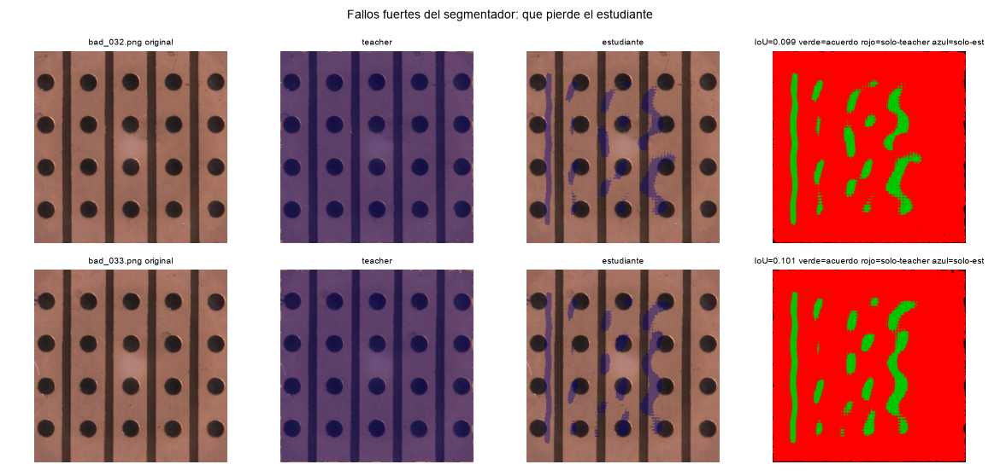

In [ ]:
# §20 Proposito: inspeccion visual de los fallos fuertes del segmentador (bad_032/033, IoU~0.1). Mide acuerdo con teacher, no correccion humana.
mo.stop(CAPTURE_MODE, mo.md("omitida en modo captura"))
tic("fallos_seg")
_f20 = ["bad_032.png", "bad_033.png"]
_path20 = dict(zip(df_files.filename, df_files.path))
_fg20, _ax20 = plt.subplots(len(_f20), 4, figsize=(13, 3.1 * len(_f20)), squeeze=False)
_fg20.patch.set_facecolor("white")
for _k20, _ff in enumerate(_f20):
    _im20 = Image.open(_path20[_ff]).convert("RGB")
    _tm20 = np.array(Image.open(teacher_mask_dir / _ff)) > 127
    _sm20 = np.array(Image.open(MODELS_DIR / "student" / "masks_png" / _ff)) > 127
    _ag20 = _tm20 & _sm20
    _df20 = np.zeros((*_tm20.shape, 3), np.uint8)
    _df20[_ag20] = (0, 200, 0)
    _df20[_tm20 & ~_sm20] = (255, 0, 0)
    _df20[_sm20 & ~_tm20] = (0, 120, 255)
    _iou20 = float(_ag20.sum() / max(int((_tm20 | _sm20).sum()), 1))
    _ax20[_k20][0].imshow(_im20)
    _ax20[_k20][0].set_title(_ff + " original", fontsize=8, color="black")
    _ax20[_k20][1].imshow(_im20)
    _ax20[_k20][1].imshow(np.ma.masked_where(~_tm20[::4, ::4], np.ones(_tm20[::4, ::4].shape)), cmap="jet", alpha=0.4, extent=(0, _im20.size[0], _im20.size[1], 0))
    _ax20[_k20][1].set_title("teacher", fontsize=8, color="black")
    _ax20[_k20][2].imshow(_im20)
    _ax20[_k20][2].imshow(np.ma.masked_where(~_sm20[::4, ::4], np.ones(_sm20[::4, ::4].shape)), cmap="jet", alpha=0.4, extent=(0, _im20.size[0], _im20.size[1], 0))
    _ax20[_k20][2].set_title("estudiante", fontsize=8, color="black")
    _ax20[_k20][3].imshow(_df20)
    _ax20[_k20][3].set_title("IoU=%.3f verde=acuerdo rojo=solo-teacher azul=solo-est" % _iou20, fontsize=8, color="black")
    [_aa.axis("off") for _aa in _ax20[_k20]]
_fg20.suptitle("Fallos fuertes del segmentador: que pierde el estudiante", fontsize=11, color="black")
_fg20.tight_layout()
_fg20.savefig(FIG_DIR / "fallos_segmentador.png", dpi=90)
print("saved fallos_segmentador.png")
toc("fallos_seg")
mo.image(str(FIG_DIR / "fallos_segmentador.png"))